# Khảo Sát và Phân Tích Dữ Liệu Khám Phá (EDA)
## Hệ Thống Dự Báo Nhu Cầu Tiêu Thụ và Tối Ưu Tồn Kho 6 Danh Mục HairCare

---
### Cấu trúc nghiên cứu thực nghiệm
- **Module 1:** Tổng Quan Dữ Liệu và Đánh Giá Chất Lượng *(Missing values, Outliers, Zero-sale distribution, Continuity)*  
- **Module 2:** Phân Tích Chuỗi Thời Gian và Tính Quy Luật *(Time Series, Rolling Mean, STL Decomposition, Day-of-Week, Holiday effects)*  
- **Module 3:** Phân Tích Cơ Cấu và Động Lực Theo 6 Danh Mục Sản Phẩm *(Revenue contribution, Monthly category dynamics)*  
- **Module 4:** Phân Tích Đơn Giá và Đại Diện Khuyến Mãi *(Price distribution, Price elasticity of demand, Promotion proxy)*  
- **Module 5:** Phân Khúc SKU và Nhận Diện Sản Phẩm Mới *(Active days distribution, Pareto curve, K-Means clustering)*  
- **Module 6:** Trích Xuất Đặc Trưng và Đánh Giá Mức Độ Quan Trọng *(ACF/PACF, Lag correlations, Random Forest MDI Feature Importance)*  
- **Module 7:** Phân Tích Định Lượng Điểm Dị Biệt và Chiến Lược Kiểm Soát Dữ Liệu *(Bulk spikes, Indicator flags, Censored month, Seasonality index)*  
- **Module 8:** Tổng Kết Toàn Diện và Thiết Kế Kiến Trúc Mô Hình Dự Báo 2 Tầng *(Tier 1 Macro Forecast, Tier 2 SKU Allocation, Tier 3 Inventory Reorder, Feature Store Matrix)*  


In [79]:
# ============================================================
# SETUP — Import thư viện và cấu hình chung
# ============================================================
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import tempfile

# Cấu hình thư mục tạm cho Matplotlib trên Windows
mpl_dir = os.path.join(tempfile.gettempdir(), 'mpl_cache')
os.makedirs(mpl_dir, exist_ok=True)
os.environ['MPLCONFIGDIR'] = mpl_dir

try:
    from IPython.display import display
except ImportError:
    display = print

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

# --- Style ---
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
sns.set_theme(style='whitegrid', palette='tab10')

# --- Màu sắc theo danh mục ---
CATEGORY_COLORS = {
    'hairstyling': '#1f77b4',
    'shampoo':     '#ff7f0e',
    'hairmask':    '#2ca02c',
    'conditioner': '#d62728',
    'treatment':   '#9467bd',
    'dry shampoo': '#8c564b',
}
CATEGORY_VI = {
    'hairstyling': 'Tạo kiểu tóc',
    'shampoo':     'Dầu gội',
    'hairmask':    'Ủ tóc',
    'conditioner': 'Dầu xả',
    'treatment':   'Dưỡng tóc',
    'dry shampoo': 'Dầu gội khô',
}

# --- Tìm đường dẫn data linh hoạt ---
candidate_bases = [
    os.path.join(os.getcwd(), 'data', 'ml', 'processed'),
    os.path.join(os.getcwd(), '..', 'data', 'ml', 'processed'),
    os.path.join(os.path.dirname(os.getcwd()), 'data', 'ml', 'processed'),
    r'c:\Users\Acer\PycharmProjects\ML-WEB\data\ml\processed'
]
BASE = next((p for p in candidate_bases if os.path.exists(p)), candidate_bases[-1])

SALES_PATH   = os.path.join(BASE, 'haircare_demo_daily_sales.csv')
MAPPING_PATH = os.path.join(BASE, 'haircare_demo_product_mapping.csv')
CATALOG_PATH = os.path.join(BASE, 'haircare_catalog_cleaned.csv')
PROD_PATH    = os.path.join(BASE, 'eda_product_summary.csv')
CAT_PATH     = os.path.join(BASE, 'eda_category_summary.csv')
MONTH_PATH   = os.path.join(BASE, 'eda_monthly_summary.csv')

# Tạo thư mục lưu biểu đồ
if os.path.basename(os.getcwd()) == 'EDA':
    FIG_DIR = os.path.join(os.getcwd(), 'figures')
else:
    FIG_DIR = os.path.join(os.getcwd(), 'EDA', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

print('Hoàn tất cấu hình môi trường thực nghiệm.')
print(f'Thư mục dữ liệu: {BASE}')
print(f'Thư mục lưu trữ biểu đồ: {FIG_DIR}')


Hoàn tất cấu hình môi trường thực nghiệm.
Thư mục dữ liệu: C:\Users\Acer\PycharmProjects\ML-WEB\EDA\..\data\ml\processed
Thư mục lưu trữ biểu đồ: C:\Users\Acer\PycharmProjects\ML-WEB\EDA\figures


In [80]:
# ============================================================
# LOAD DATA
# ============================================================
df = pd.read_csv(SALES_PATH, encoding='utf-8', parse_dates=['sale_date'])
df_map  = pd.read_csv(MAPPING_PATH, encoding='utf-8')
df_cat  = pd.read_csv(CAT_PATH,     encoding='utf-8')
df_month= pd.read_csv(MONTH_PATH,   encoding='utf-8')
df_prod = pd.read_csv(PROD_PATH,    encoding='utf-8')

# Catalog (giá USD)
try:
    df_catalog = pd.read_csv(CATALOG_PATH, encoding='utf-8')
except:
    df_catalog = pd.DataFrame()

# Đảm bảo sort theo ngày
df = df.sort_values(['product_id', 'sale_date']).reset_index(drop=True)

print(f'Kích thước dữ liệu bán hàng hàng ngày: {df.shape}')
print(f'Khoảng thời gian khảo sát: {df["sale_date"].min().date()} đến {df["sale_date"].max().date()}')
print(f'Số lượng SKU khảo sát: {df["product_id"].nunique()}')
print(f'Số lượng danh mục sản phẩm: {df["category"].nunique()}')
df.head()

Kích thước dữ liệu bán hàng hàng ngày: (43601, 16)
Khoảng thời gian khảo sát: 2009-12-01 đến 2011-12-09
Số lượng SKU khảo sát: 59
Số lượng danh mục sản phẩm: 6


,sale_date,product_id,quantity_sold,revenue_gbp,source_order_count,unit_price_gbp,outlier_source_lines,category,category_vi,product_name,source_availability,currency,source_dataset,is_simulated,label_is_simulated,is_zero_sale_day
0,2009-12-01,8161090633945,261,702.42,18,3.010556,0,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False
1,2009-12-02,8161090633945,750,1953.99,18,3.032778,1,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False
2,2009-12-03,8161090633945,359,988.43,22,3.035909,0,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False
3,2009-12-04,8161090633945,179,489.65,13,2.919231,0,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False
4,2009-12-05,8161090633945,96,249.60,6,2.683333,0,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False


---
## Module 1 — Tổng Quan Dữ Liệu và Đánh Giá Chất Lượng

Khảo sát cấu trúc tổng thể của tập dữ liệu panel, kiểm định tính toàn vẹn thông qua tỷ lệ giá trị khuyết thiếu (missing values), phân phối các ngày không phát sinh doanh số (zero-sale days), nhận diện các giá trị ngoại lai (outliers) và tính liên tục của chuỗi thời gian.


In [81]:
# ── 1.1 Thống kê mô tả cơ bản ──────────────────────────────
print('=== Thống kê mô tả các cột số ===')
display(df[['quantity_sold', 'revenue_gbp', 'unit_price_gbp', 'source_order_count']].describe().round(2))

=== Thống kê mô tả các cột số ===


,quantity_sold,revenue_gbp,unit_price_gbp,source_order_count
count,43601.00,43601.00,31066.00,43601.00
mean,39.47,83.17,3.13,2.84
std,96.78,201.22,2.78,2.94
min,0.00,0.00,0.41,0.00
25%,0.00,0.00,1.63,0.00
50%,12.00,28.55,2.16,2.00
75%,40.00,87.03,3.58,4.00
max,4314.00,8656.00,26.04,31.00


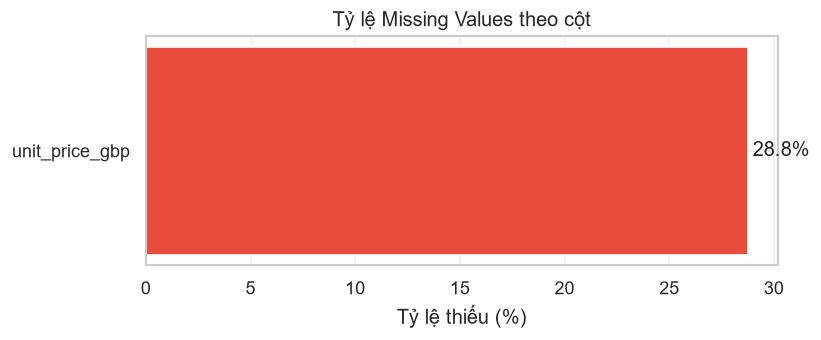


Kết luận phân tích:
  - Biến unit_price_gbp khuyết thiếu 28.7%, hoàn toàn xuất phát từ các bản ghi có quantity_sold = 0.
  - Đề xuất kỹ thuật: Thực hiện phép thế (imputation) bằng giá trị trung vị (median price) lịch sử của từng SKU.


,column,missing_count,missing_pct
5,unit_price_gbp,12535,28.75


In [82]:
# ── 1.2 Missing Values ──────────────────────────────────────
missing = df.isnull().sum().reset_index()
missing.columns = ['column', 'missing_count']
missing['missing_pct'] = (missing['missing_count'] / len(df) * 100).round(2)
missing = missing[missing['missing_count'] > 0]

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(missing['column'], missing['missing_pct'], color='#e74c3c', edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in missing['missing_pct']], padding=3)
ax.set_xlabel('Tỷ lệ thiếu (%)')
ax.set_title('Tỷ lệ Missing Values theo cột')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_missing_values.png'), bbox_inches='tight')
plt.show()

print('\nKết luận phân tích:')
print('  - Biến unit_price_gbp khuyết thiếu 28.7%, hoàn toàn xuất phát từ các bản ghi có quantity_sold = 0.')
print('  - Đề xuất kỹ thuật: Thực hiện phép thế (imputation) bằng giá trị trung vị (median price) lịch sử của từng SKU.')
display(missing)

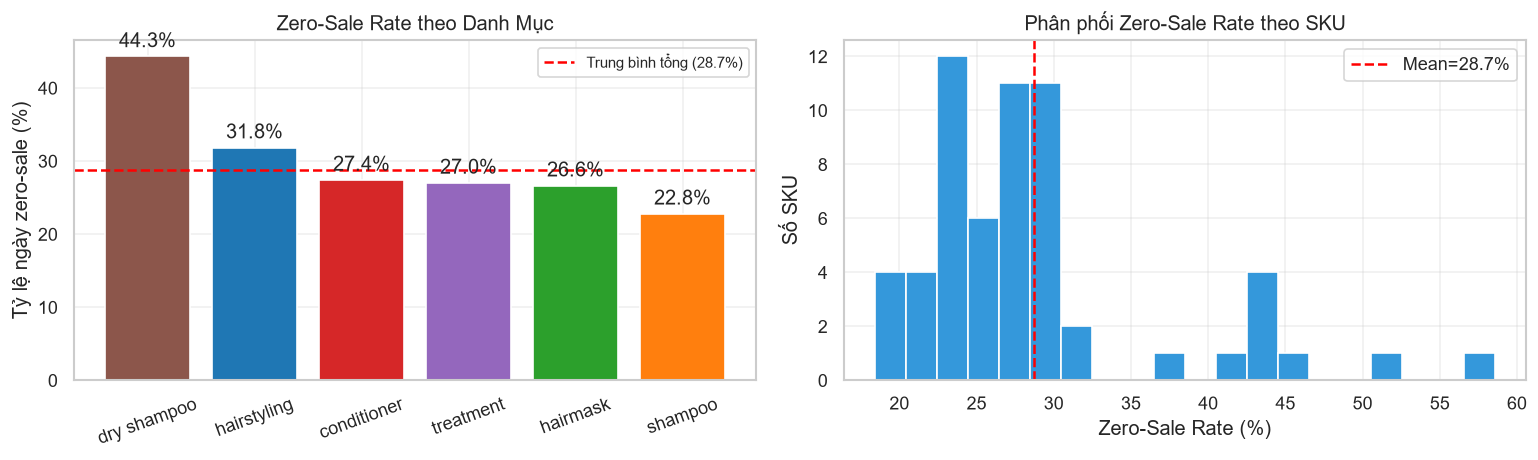


Kết luận phân tích:
  - Danh mục Dry Shampoo có tỷ lệ zero-sale cao nhất (44.3%) do số lượng SKU giới hạn (2 SKU) và tính gián đoạn của nhu cầu.
  - Danh mục Shampoo có tỷ lệ zero-sale thấp nhất (22.8%), phản ánh nhu cầu tiêu thụ có tính ổn định cao.
  - Các ngày không phát sinh doanh số (quantity_sold = 0) phản ánh thông tin nhu cầu thực tế và được bảo lưu trong tập huấn luyện.


In [83]:
# ── 1.3 Phân phối Zero-Sale Days ────────────────────────────
zero_rate_cat = (
    df.groupby('category')['is_zero_sale_day']
    .agg(['sum', 'count'])
    .assign(zero_rate=lambda x: x['sum'] / x['count'] * 100)
    .sort_values('zero_rate', ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Bar: zero-rate theo category
colors = [CATEGORY_COLORS[c] for c in zero_rate_cat['category']]
bars = axes[0].bar(zero_rate_cat['category'], zero_rate_cat['zero_rate'],
                   color=colors, edgecolor='white')
axes[0].bar_label(bars, labels=[f"{v:.1f}%" for v in zero_rate_cat['zero_rate']], padding=3)
axes[0].axhline(df['is_zero_sale_day'].mean() * 100, color='red', linestyle='--',
                label=f"Trung bình tổng ({df['is_zero_sale_day'].mean()*100:.1f}%)")
axes[0].set_ylabel('Tỷ lệ ngày zero-sale (%)')
axes[0].set_title('Zero-Sale Rate theo Danh Mục')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(fontsize=9)

# Zero-sale rate theo SKU histogram
zero_sku = df.groupby('product_id')['is_zero_sale_day'].mean() * 100
axes[1].hist(zero_sku, bins=20, color='#3498db', edgecolor='white')
axes[1].axvline(zero_sku.mean(), color='red', linestyle='--', label=f"Mean={zero_sku.mean():.1f}%")
axes[1].set_xlabel('Zero-Sale Rate (%)')
axes[1].set_ylabel('Số SKU')
axes[1].set_title('Phân phối Zero-Sale Rate theo SKU')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_zero_sale_rate.png'), bbox_inches='tight')
plt.show()

print('\nKết luận phân tích:')
print('  - Danh mục Dry Shampoo có tỷ lệ zero-sale cao nhất (44.3%) do số lượng SKU giới hạn (2 SKU) và tính gián đoạn của nhu cầu.')
print('  - Danh mục Shampoo có tỷ lệ zero-sale thấp nhất (22.8%), phản ánh nhu cầu tiêu thụ có tính ổn định cao.')
print('  - Các ngày không phát sinh doanh số (quantity_sold = 0) phản ánh thông tin nhu cầu thực tế và được bảo lưu trong tập huấn luyện.')


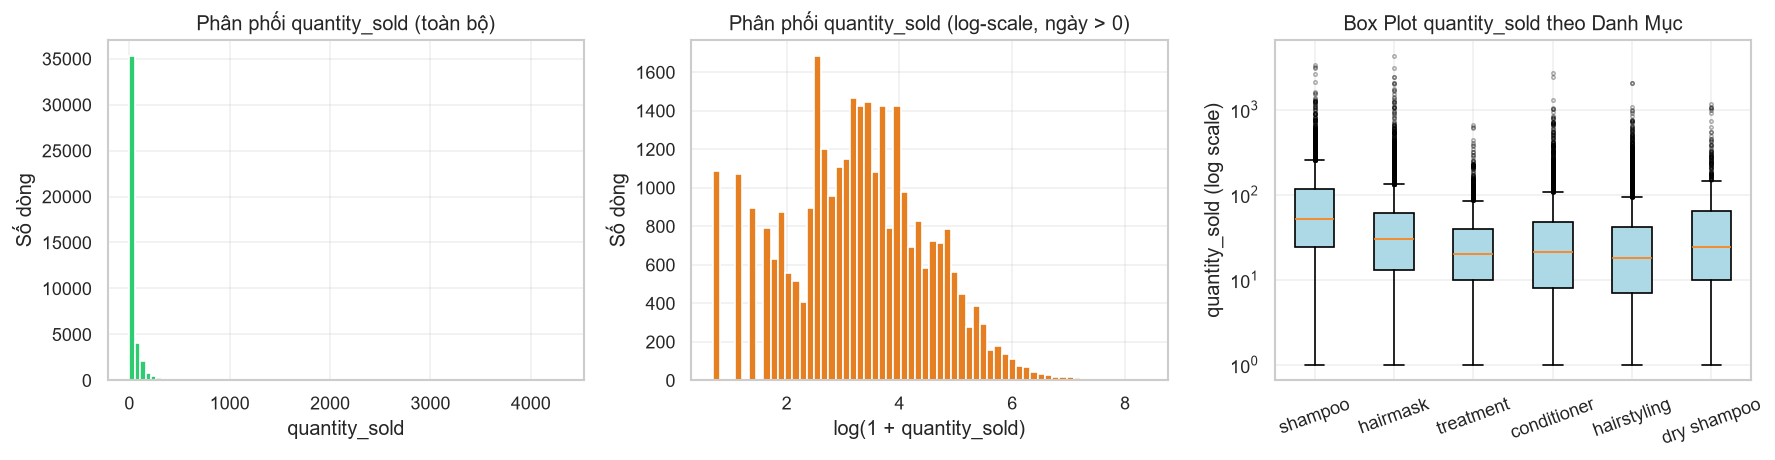


Kết luận phân tích:
  - Phân phối số lượng bán (quantity_sold) lệch phải rõ rệt: mean = 39.5, max = 4,314.
  - Ngưỡng phân vị P99 = 381 đơn vị, xác định 433 bản ghi ngoại lai (0.99% tổng số dòng).
  - Đề xuất kỹ thuật: Áp dụng hàm mất mát Robust (Huber loss) hoặc phép biến đổi logarit để kiểm soát ảnh hưởng của ngoại lai.


In [84]:
# ── 1.4 Phân phối quantity_sold và phát hiện Outliers ───────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram (full)
axes[0].hist(df['quantity_sold'], bins=80, color='#2ecc71', edgecolor='white')
axes[0].set_xlabel('quantity_sold')
axes[0].set_ylabel('Số dòng')
axes[0].set_title('Phân phối quantity_sold (toàn bộ)')

# Histogram (log scale)
non_zero = df[df['quantity_sold'] > 0]['quantity_sold']
axes[1].hist(np.log1p(non_zero), bins=60, color='#e67e22', edgecolor='white')
axes[1].set_xlabel('log(1 + quantity_sold)')
axes[1].set_ylabel('Số dòng')
axes[1].set_title('Phân phối quantity_sold (log-scale, ngày > 0)')

# Box plot theo category
cat_order = df.groupby('category')['quantity_sold'].median().sort_values(ascending=False).index
df_nonzero = df[df['quantity_sold'] > 0]
axes[2].boxplot(
    [df_nonzero[df_nonzero['category'] == c]['quantity_sold'].values for c in cat_order],
    tick_labels=cat_order,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue'),
    flierprops=dict(marker='o', markersize=2, alpha=0.3)
)
axes[2].set_yscale('log')
axes[2].set_ylabel('quantity_sold (log scale)')
axes[2].set_title('Box Plot quantity_sold theo Danh Mục')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_quantity_distribution.png'), bbox_inches='tight')
plt.show()

# Thống kê outlier
q99 = df['quantity_sold'].quantile(0.99)
outliers = df[df['quantity_sold'] > q99]
print('\nKết luận phân tích:')
print(f'  - Phân phối số lượng bán (quantity_sold) lệch phải rõ rệt: mean = {df["quantity_sold"].mean():.1f}, max = {df["quantity_sold"].max():,}.')
print(f'  - Ngưỡng phân vị P99 = {q99:.0f} đơn vị, xác định {len(outliers)} bản ghi ngoại lai ({len(outliers)/len(df)*100:.2f}% tổng số dòng).')
print('  - Đề xuất kỹ thuật: Áp dụng hàm mất mát Robust (Huber loss) hoặc phép biến đổi logarit để kiểm soát ảnh hưởng của ngoại lai.')


Tổng số ngày theo lịch: 739
Số ngày hiện diện trong dữ liệu: 739
Số ngày bị gián đoạn: 0
Chuỗi thời gian liên tục 100%, không xuất hiện gián đoạn ngày.



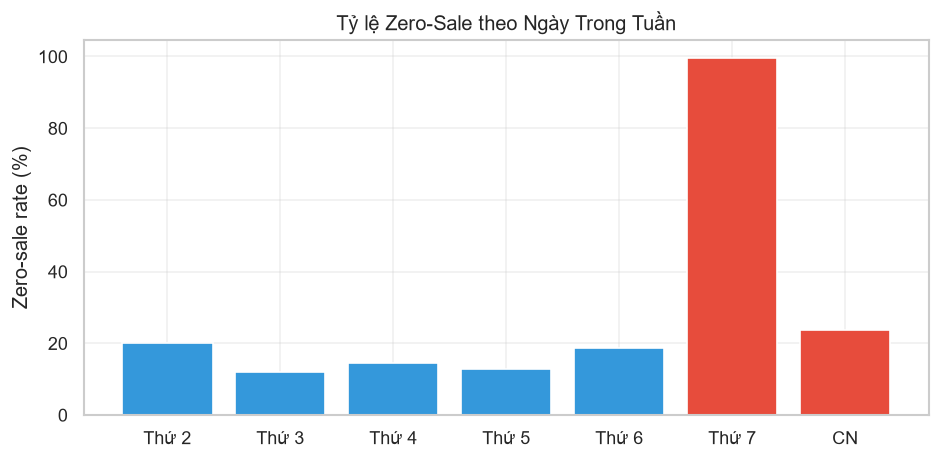

Kết luận phân tích: Xác suất ngày không có đơn hàng tăng cao vào Thứ 7 và Chủ Nhật, phản ánh tính chu kỳ theo tuần.
   Đặc trưng day_of_week là quan trọng và nên được mã hóa.


In [85]:
# ── 1.5 Kiểm tra tính liên tục của chuỗi thời gian ─────────
date_range = pd.date_range(df['sale_date'].min(), df['sale_date'].max(), freq='D')
dates_in_data = df['sale_date'].unique()
missing_dates = set(date_range) - set(dates_in_data)

print(f'Tổng số ngày theo lịch: {len(date_range)}')
print(f'Số ngày hiện diện trong dữ liệu: {len(dates_in_data)}')
print(f'Số ngày bị gián đoạn: {len(missing_dates)}')

if missing_dates:
    print('   Các ngày thiếu:', sorted(missing_dates)[:10])
else:
    print('Chuỗi thời gian liên tục 100%, không xuất hiện gián đoạn ngày.')

print()

# Phân phối theo ngày trong tuần
df['day_of_week'] = df['sale_date'].dt.day_of_week
dow_zero = df.groupby('day_of_week')['is_zero_sale_day'].mean() * 100
dow_names = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'CN']

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dow_names, dow_zero.values, color=['#3498db']*5 + ['#e74c3c']*2, edgecolor='white')
ax.set_ylabel('Zero-sale rate (%)')
ax.set_title('Tỷ lệ Zero-Sale theo Ngày Trong Tuần')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_dow_zero_rate.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích: Xác suất ngày không có đơn hàng tăng cao vào Thứ 7 và Chủ Nhật, phản ánh tính chu kỳ theo tuần.')
print('   Đặc trưng day_of_week là quan trọng và nên được mã hóa.')

---
## Module 2 — Phân Tích Chuỗi Thời Gian và Tính Quy Luật

Khám phá xu hướng dài hạn (trend), tính mùa vụ theo chu kỳ năm và tuần (seasonality), hiệu ứng ngày trong tuần (day-of-week effect) và tác động của các kỳ nghỉ lễ chính thức tại Anh (UK public holidays).


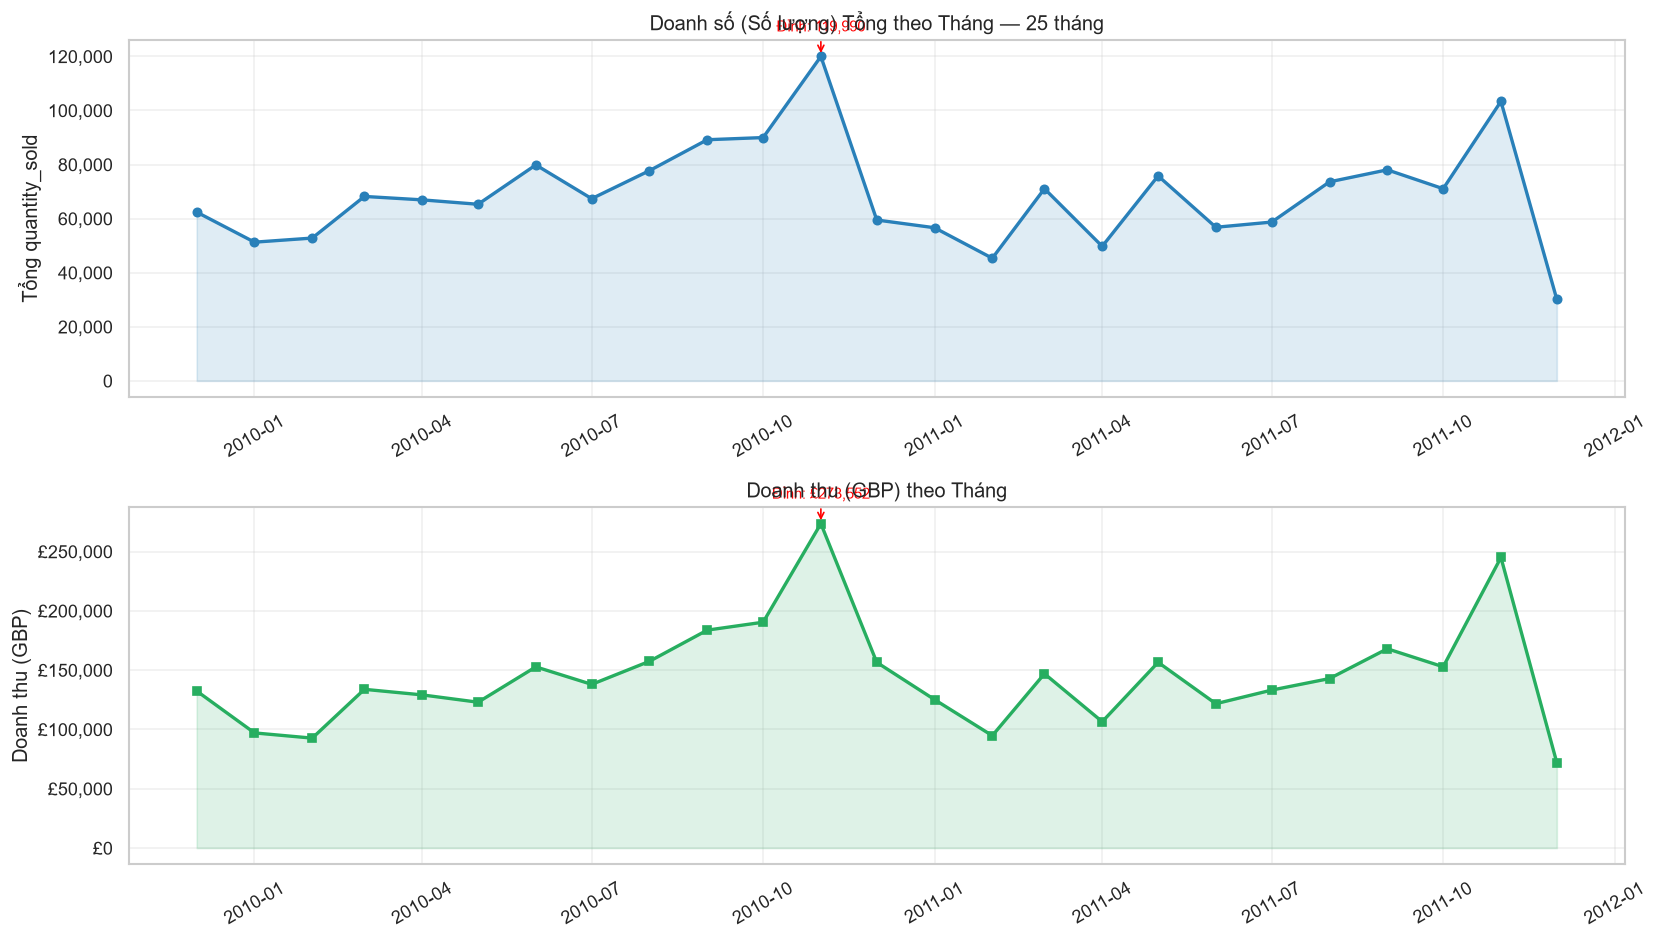

Kết luận phân tích:
  - Xu hướng doanh thu tổng thể tăng trưởng từ đầu năm 2010 đến cuối năm 2011.
  - Đỉnh mùa vụ xuất hiện rõ rệt vào Tháng 11 hàng năm (mùa mua sắm trước kỳ nghỉ lễ và sự kiện Black Friday).
  - Dữ liệu Tháng 12/2011 chỉ ghi nhận 9 ngày (cắt cụt), cần loại trừ khỏi tập đánh giá cấp tháng (Monthly Backtest).


In [86]:
# ── 2.1 Doanh số tổng theo tháng (toàn bộ 25 tháng) ────────
df_month['month_dt'] = pd.to_datetime(df_month['month'] + '-01')

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Quantity
axes[0].plot(df_month['month_dt'], df_month['quantity_sold'],
             marker='o', markersize=5, color='#2980b9', linewidth=2)
axes[0].fill_between(df_month['month_dt'], df_month['quantity_sold'], alpha=0.15, color='#2980b9')
# Đánh dấu đỉnh
peak_idx = df_month['quantity_sold'].idxmax()
axes[0].annotate(f"Đỉnh: {df_month.loc[peak_idx,'quantity_sold']:,}",
                 xy=(df_month.loc[peak_idx,'month_dt'], df_month.loc[peak_idx,'quantity_sold']),
                 xytext=(0, 15), textcoords='offset points', ha='center',
                 fontsize=9, color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))
axes[0].set_ylabel('Tổng quantity_sold')
axes[0].set_title('Doanh số (Số lượng) Tổng theo Tháng — 25 tháng')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Revenue
axes[1].plot(df_month['month_dt'], df_month['revenue_gbp'],
             marker='s', markersize=5, color='#27ae60', linewidth=2)
axes[1].fill_between(df_month['month_dt'], df_month['revenue_gbp'], alpha=0.15, color='#27ae60')
peak_rev_idx = df_month['revenue_gbp'].idxmax()
axes[1].annotate(f"Đỉnh: £{df_month.loc[peak_rev_idx,'revenue_gbp']:,.0f}",
                 xy=(df_month.loc[peak_rev_idx,'month_dt'], df_month.loc[peak_rev_idx,'revenue_gbp']),
                 xytext=(0, 15), textcoords='offset points', ha='center',
                 fontsize=9, color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))
axes[1].set_ylabel('Doanh thu (GBP)')
axes[1].set_title('Doanh thu (GBP) theo Tháng')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))

for ax in axes:
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_monthly_timeseries.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Xu hướng doanh thu tổng thể tăng trưởng từ đầu năm 2010 đến cuối năm 2011.')
print('  - Đỉnh mùa vụ xuất hiện rõ rệt vào Tháng 11 hàng năm (mùa mua sắm trước kỳ nghỉ lễ và sự kiện Black Friday).')
print('  - Dữ liệu Tháng 12/2011 chỉ ghi nhận 9 ngày (cắt cụt), cần loại trừ khỏi tập đánh giá cấp tháng (Monthly Backtest).')


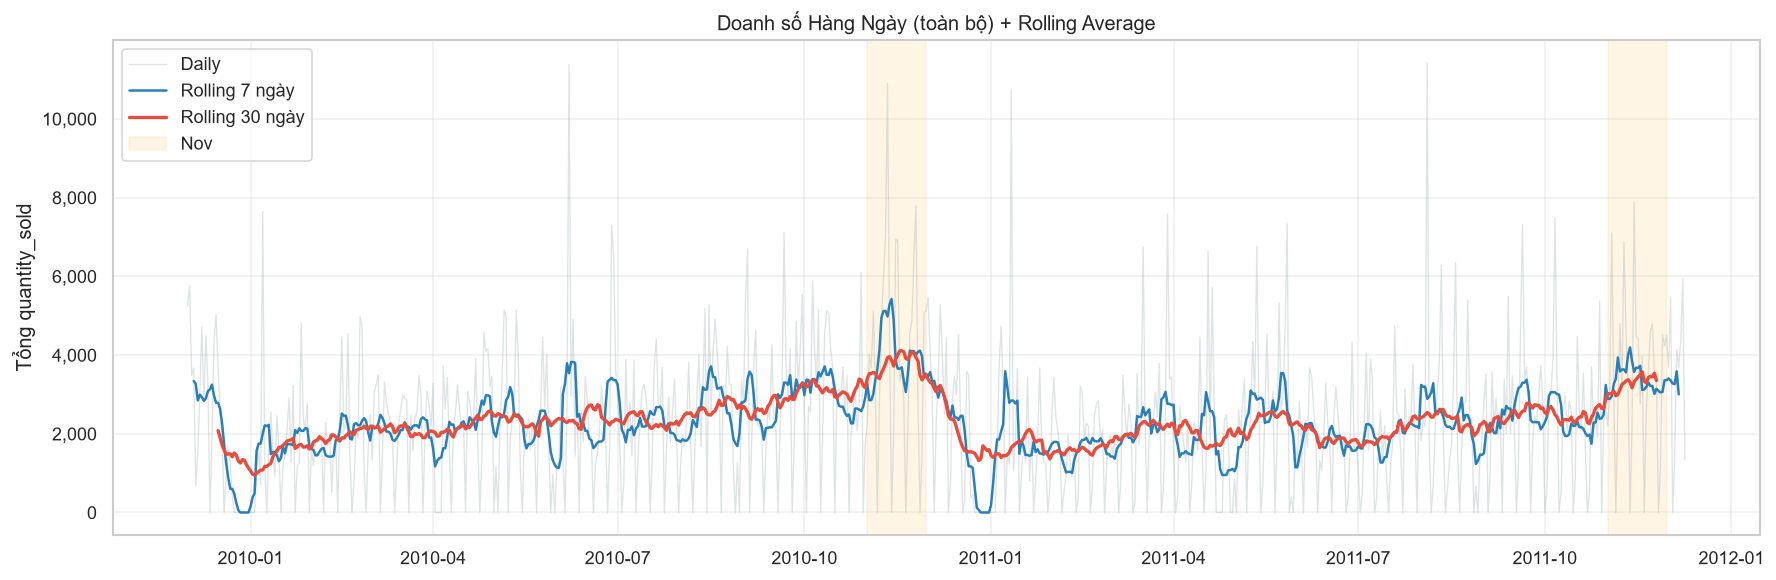

In [87]:
# ── 2.2 Doanh số Daily tổng + Rolling Mean ───────────────────
daily_total = df.groupby('sale_date')['quantity_sold'].sum().reset_index()
daily_total['rolling_7']  = daily_total['quantity_sold'].rolling(7,  center=True).mean()
daily_total['rolling_30'] = daily_total['quantity_sold'].rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_total['sale_date'], daily_total['quantity_sold'],
        alpha=0.3, color='#95a5a6', linewidth=0.8, label='Daily')
ax.plot(daily_total['sale_date'], daily_total['rolling_7'],
        color='#2980b9', linewidth=1.5, label='Rolling 7 ngày')
ax.plot(daily_total['sale_date'], daily_total['rolling_30'],
        color='#e74c3c', linewidth=2, label='Rolling 30 ngày')

# Đánh dấu tháng 11 peak
for yr in [2010, 2011]:
    ax.axvspan(pd.Timestamp(f'{yr}-11-01'), pd.Timestamp(f'{yr}-11-30'),
               alpha=0.1, color='orange', label='Nov' if yr == 2010 else '')

ax.set_ylabel('Tổng quantity_sold')
ax.set_title('Doanh số Hàng Ngày (toàn bộ) + Rolling Average')
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_daily_rolling.png'), bbox_inches='tight')
plt.show()

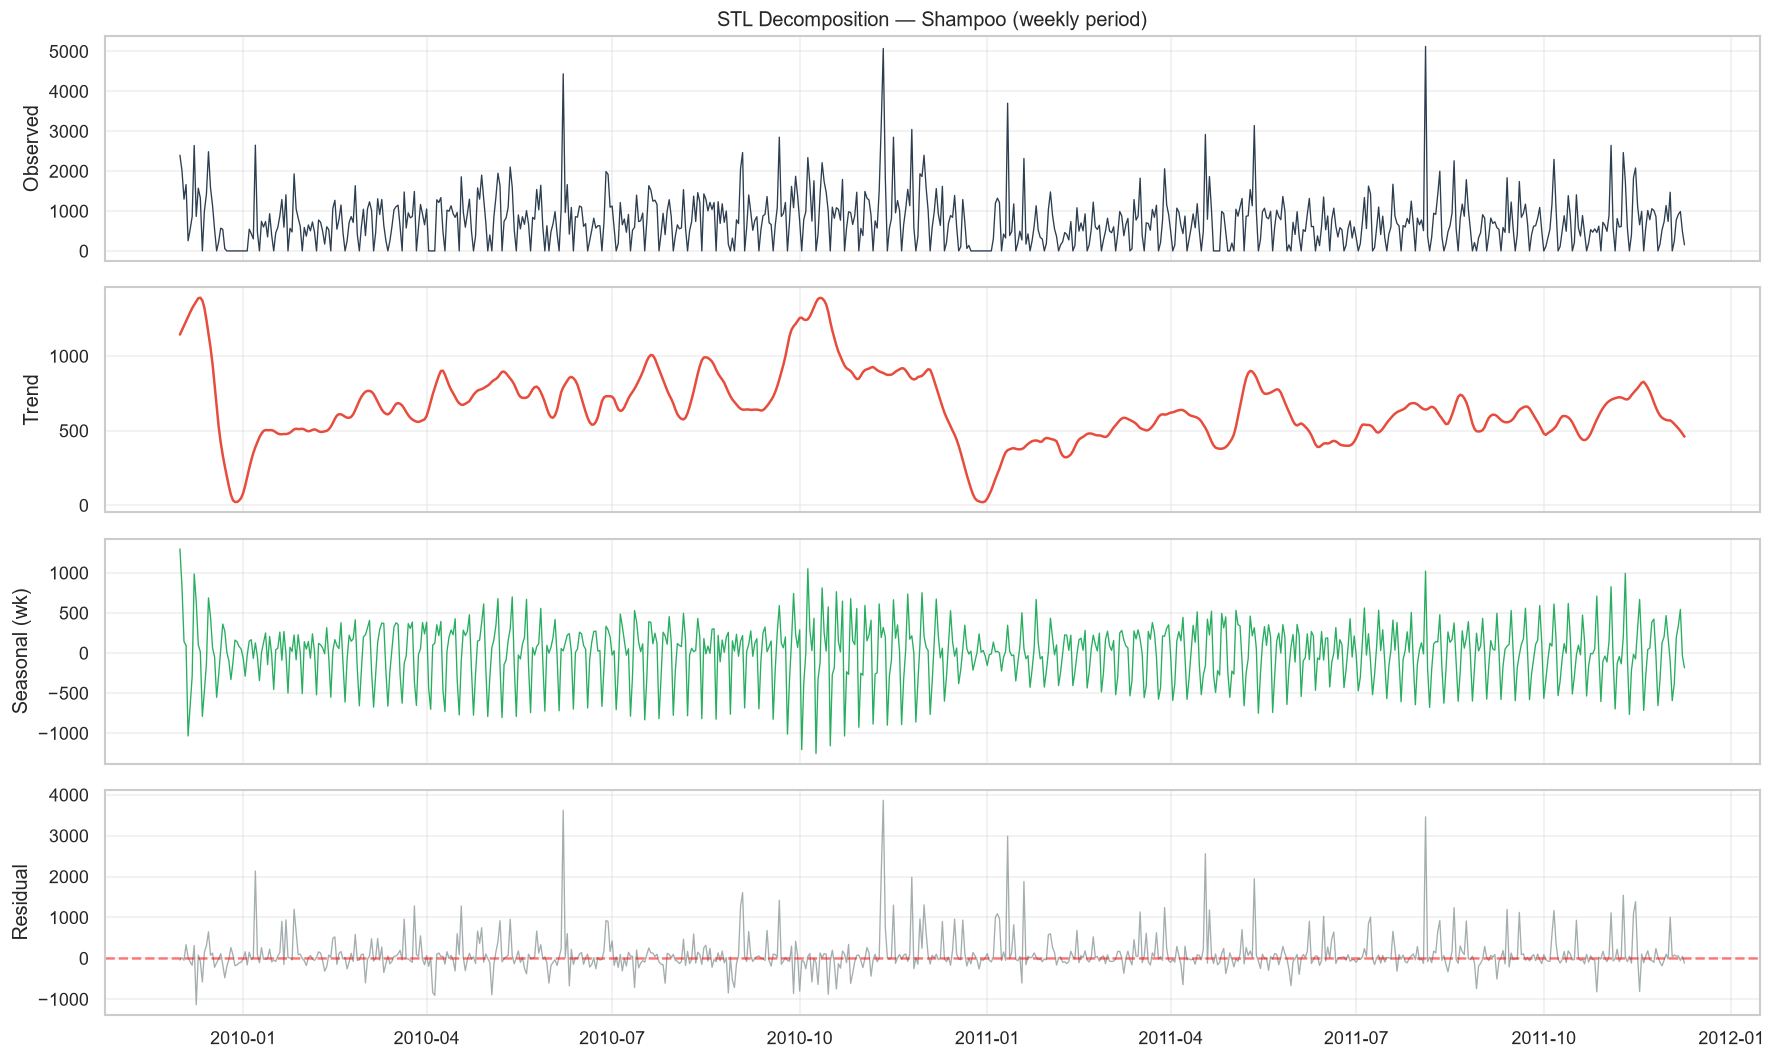

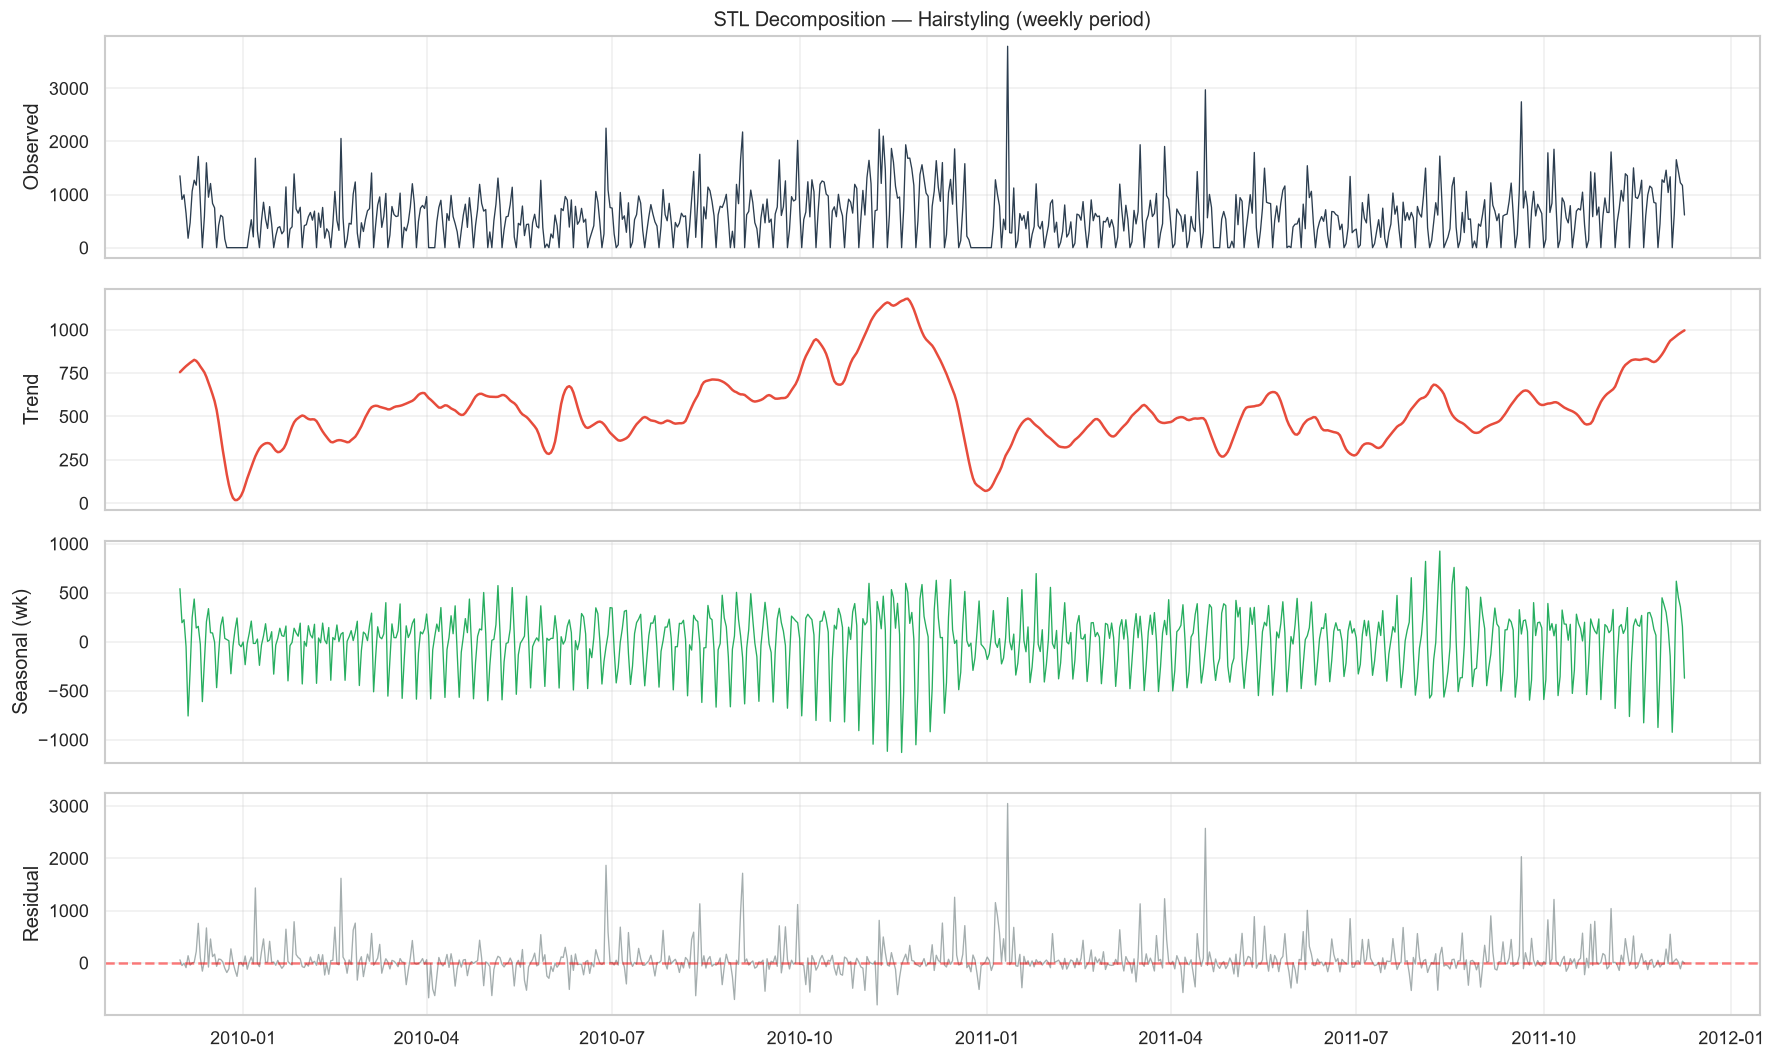

Kết luận phân tích:
  - Thành phần xu hướng (Trend component) thể hiện sự tăng trưởng nhất quán theo thời gian.
  - Thành phần mùa vụ chu kỳ 7 ngày (Seasonality) rõ rệt, khẳng định tầm quan trọng của đặc trưng day_of_week.
  - Thành phần dư số (Residuals) xuất hiện các điểm cực trị đơn sỉ, cần kiểm soát bằng các biến cờ tín hiệu dị biệt.


In [88]:
# ── 2.3 STL Decomposition (cấp tổng) ────────────────────────
# Dùng category tổng nhất: shampoo
for cat in ['shampoo', 'hairstyling']:
    cat_daily = (
        df[df['category'] == cat]
        .groupby('sale_date')['quantity_sold'].sum()
        .asfreq('D')
        .fillna(0)
    )
    stl = STL(cat_daily, period=7, robust=True)
    result = stl.fit()

    fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
    axes[0].plot(cat_daily, color='#2c3e50', linewidth=0.8);  axes[0].set_ylabel('Observed')
    axes[1].plot(result.trend, color='#e74c3c', linewidth=1.5); axes[1].set_ylabel('Trend')
    axes[2].plot(result.seasonal, color='#27ae60', linewidth=0.8); axes[2].set_ylabel('Seasonal (wk)')
    axes[3].plot(result.resid, color='#7f8c8d', linewidth=0.8, alpha=0.7); axes[3].set_ylabel('Residual')
    axes[3].axhline(0, color='red', linestyle='--', alpha=0.5)
    axes[0].set_title(f'STL Decomposition — {cat.title()} (weekly period)')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'07_stl_{cat}.png'), bbox_inches='tight')
    plt.show()

print('Kết luận phân tích:')
print('  - Thành phần xu hướng (Trend component) thể hiện sự tăng trưởng nhất quán theo thời gian.')
print('  - Thành phần mùa vụ chu kỳ 7 ngày (Seasonality) rõ rệt, khẳng định tầm quan trọng của đặc trưng day_of_week.')
print('  - Thành phần dư số (Residuals) xuất hiện các điểm cực trị đơn sỉ, cần kiểm soát bằng các biến cờ tín hiệu dị biệt.')


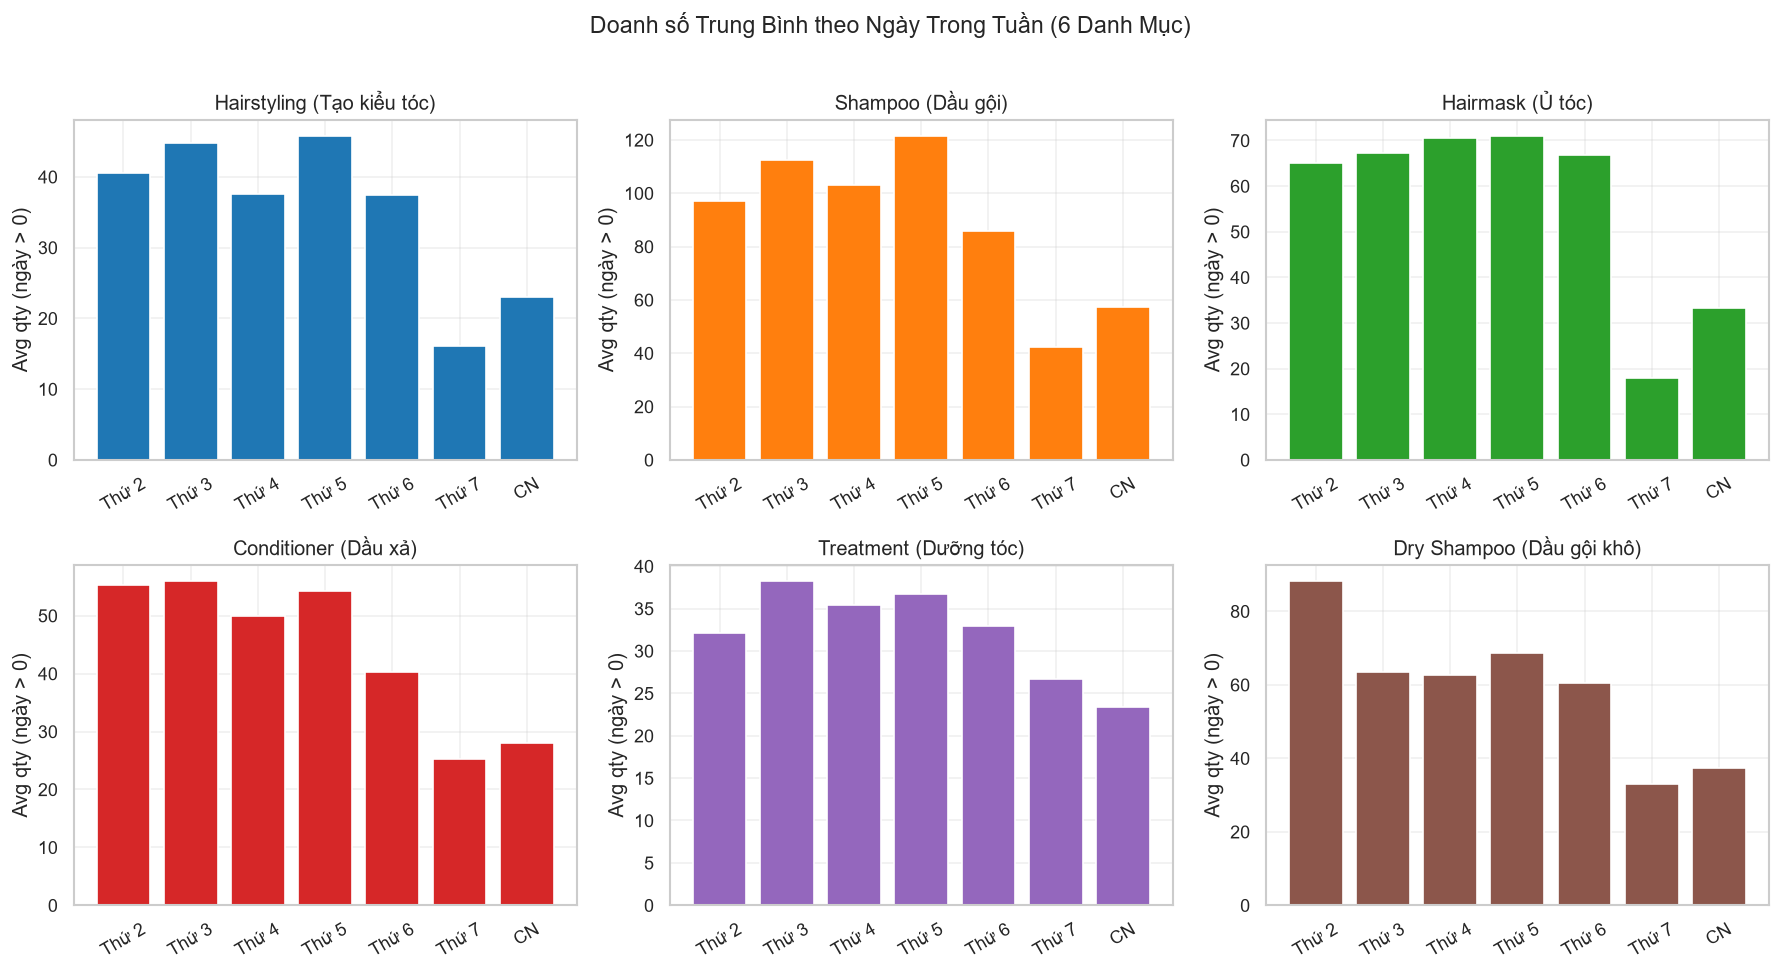

Kết luận phân tích: Doanh số hai ngày cuối tuần suy giảm đáng kể so với các ngày làm việc tiêu chuẩn.
Đề xuất kỹ thuật: Biến đổi đặc trưng day_of_week bằng các hàm điều hòa sin/cos hoặc kỹ thuật one-hot.


In [89]:
# ── 2.4 Mẫu Ngày Trong Tuần (Day-of-Week Effect) ────────────
df['day_of_week'] = df['sale_date'].dt.day_of_week
dow_names_map = {0:'Thứ 2', 1:'Thứ 3', 2:'Thứ 4', 3:'Thứ 5', 4:'Thứ 6', 5:'Thứ 7', 6:'CN'}

dow_sales = (
    df[df['quantity_sold'] > 0]
    .groupby(['day_of_week', 'category'])['quantity_sold']
    .mean()
    .reset_index()
)
dow_sales['day_name'] = dow_sales['day_of_week'].map(dow_names_map)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for idx, cat in enumerate(CATEGORY_COLORS):
    ax = axes[idx // 3][idx % 3]
    sub = dow_sales[dow_sales['category'] == cat]
    sub = sub.sort_values('day_of_week')
    ax.bar(sub['day_name'], sub['quantity_sold'],
           color=CATEGORY_COLORS[cat], edgecolor='white')
    ax.set_title(f"{cat.title()} ({CATEGORY_VI[cat]})")
    ax.set_ylabel('Avg qty (ngày > 0)')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Doanh số Trung Bình theo Ngày Trong Tuần (6 Danh Mục)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '08_dow_sales.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích: Doanh số hai ngày cuối tuần suy giảm đáng kể so với các ngày làm việc tiêu chuẩn.')
print('Đề xuất kỹ thuật: Biến đổi đặc trưng day_of_week bằng các hàm điều hòa sin/cos hoặc kỹ thuật one-hot.')


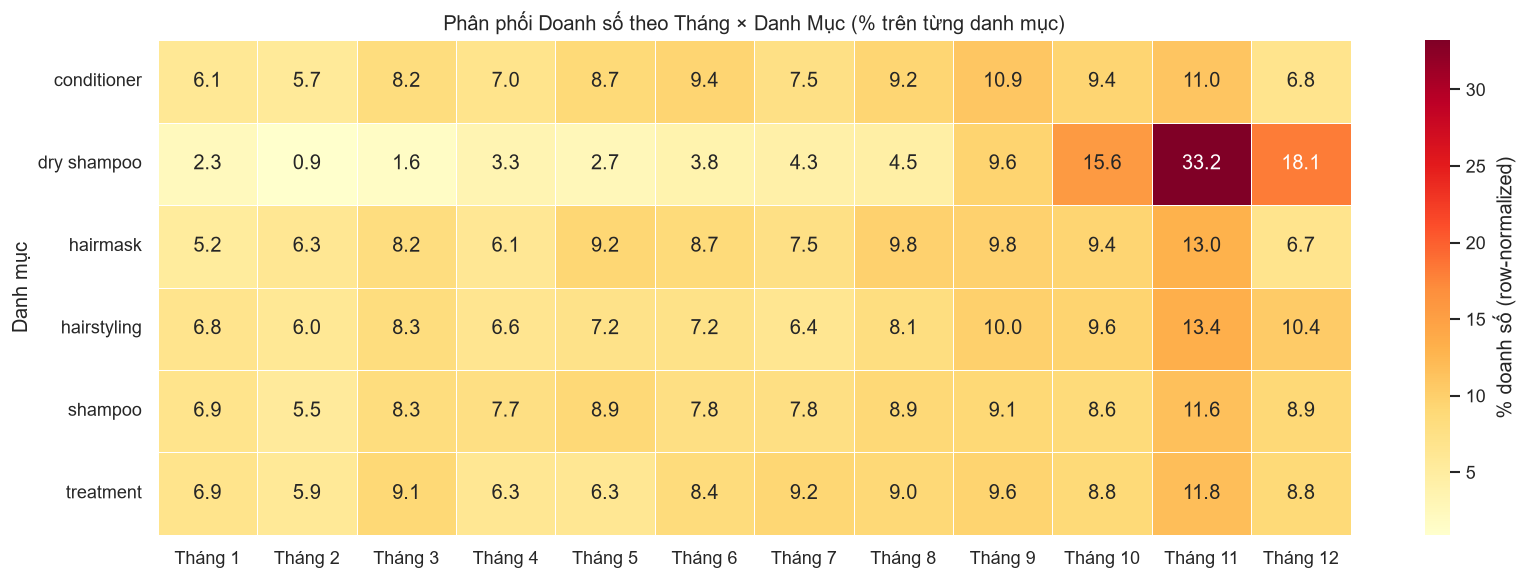

Kết luận phân tích:
  - Đỉnh điểm mùa vụ tại Tháng 11 hiện diện đồng nhất trên cả 6 danh mục sản phẩm.
  - Giai đoạn Tháng 9 - Tháng 10 ghi nhận mức tăng trưởng ổn định (chu kỳ tiêu dùng mùa thu).
  - Giai đoạn Tháng 1 - Tháng 2 ghi nhận mức suy giảm nhu cầu mang tính chu kỳ sau kỳ nghỉ lễ.


In [90]:
# ── 2.5 Heatmap Tháng × Danh Mục ────────────────────────────
df['month'] = df['sale_date'].dt.month
month_cat = (
    df.groupby(['month', 'category'])['quantity_sold'].sum()
    .reset_index()
    .pivot(index='category', columns='month', values='quantity_sold')
)
month_cat.columns = [f'Tháng {m}' for m in month_cat.columns]

# Normalize theo row để thấy mùa vụ tương đối
month_cat_norm = month_cat.div(month_cat.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(month_cat_norm, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, cbar_kws={'label': '% doanh số (row-normalized)'})
ax.set_title('Phân phối Doanh số theo Tháng × Danh Mục (% trên từng danh mục)')
ax.set_ylabel('Danh mục')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '09_heatmap_month_cat.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Đỉnh điểm mùa vụ tại Tháng 11 hiện diện đồng nhất trên cả 6 danh mục sản phẩm.')
print('  - Giai đoạn Tháng 9 - Tháng 10 ghi nhận mức tăng trưởng ổn định (chu kỳ tiêu dùng mùa thu).')
print('  - Giai đoạn Tháng 1 - Tháng 2 ghi nhận mức suy giảm nhu cầu mang tính chu kỳ sau kỳ nghỉ lễ.')


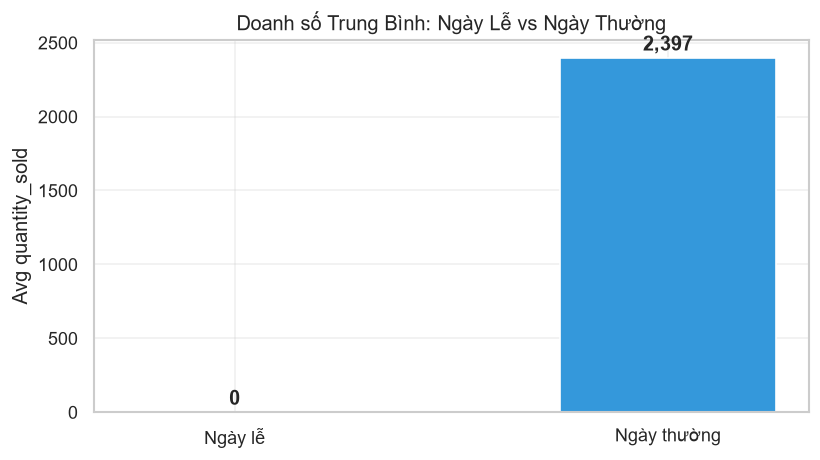

Kết luận phân tích: Doanh số trung bình trong các ngày nghỉ lễ biến động -100.0% so với các ngày tiêu chuẩn.
   → Feature is_holiday nên đưa vào mô hình.


In [91]:
# ── 2.6 Holiday Effect (UK Public Holidays) ─────────────────
# Các ngày lễ UK trong khoảng 2009-2011
uk_holidays = pd.to_datetime([
    '2009-12-25','2009-12-26','2009-12-28',  # Christmas/Boxing Day
    '2010-01-01',                              # New Year
    '2010-04-02','2010-04-05',                 # Easter
    '2010-05-03','2010-05-31',                 # Bank Holiday
    '2010-08-30',                              # Summer Bank Holiday
    '2010-12-24','2010-12-25','2010-12-26','2010-12-27',
    '2011-01-01','2011-01-03',
    '2011-04-22','2011-04-25',
    '2011-04-29',                              # Royal Wedding
    '2011-05-02','2011-05-30',
    '2011-08-29',
    '2011-12-25','2011-12-26','2011-12-27',
])

daily_total['is_holiday'] = daily_total['sale_date'].isin(uk_holidays)

holiday_mean = daily_total[daily_total['is_holiday']]['quantity_sold'].mean()
normal_mean  = daily_total[~daily_total['is_holiday']]['quantity_sold'].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Ngày lễ', 'Ngày thường'], [holiday_mean, normal_mean],
       color=['#e74c3c', '#3498db'], edgecolor='white', width=0.5)
ax.set_ylabel('Avg quantity_sold')
ax.set_title('Doanh số Trung Bình: Ngày Lễ vs Ngày Thường')
for i, v in enumerate([holiday_mean, normal_mean]):
    ax.text(i, v + 50, f'{v:,.0f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '10_holiday_effect.png'), bbox_inches='tight')
plt.show()

change_pct = (holiday_mean - normal_mean) / normal_mean * 100
print(f'Kết luận phân tích: Doanh số trung bình trong các ngày nghỉ lễ biến động {change_pct:.1f}% so với các ngày tiêu chuẩn.')
print('   → Feature is_holiday nên đưa vào mô hình.')

---
## Module 3 — Phân Tích Cơ Cấu và Động Lực Theo 6 Danh Mục Sản Phẩm

Đánh giá tỷ trọng đóng góp doanh thu, mức độ phân tán của cơ cấu danh mục và quỹ đạo tăng trưởng theo chuỗi thời gian của từng phân khúc hàng hóa.


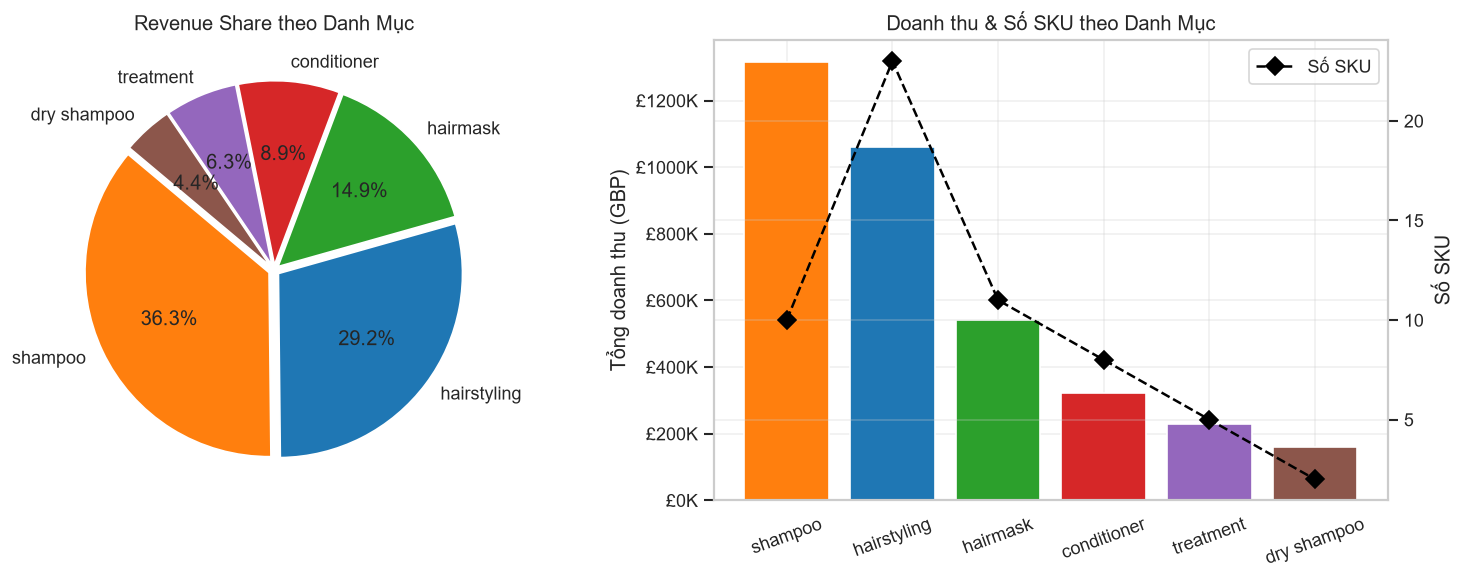

Kết luận phân tích:
  - Danh mục Shampoo chiếm tỷ trọng doanh thu lớn nhất (36.3%) chỉ với 10 SKU, đặc trưng bởi đơn giá cao và cầu ổn định.
  - Danh mục Hairstyling sở hữu số lượng SKU nhiều nhất (23 SKU, chiếm 29.2% doanh thu), phản ánh tính phân tán cao.
  - Danh mục Dry Shampoo đóng góp tỷ trọng nhỏ nhất (4.4%) với 2 SKU, thuộc dạng nhu cầu thưa thớt (sparse demand).


In [92]:
# ── 3.1 Revenue Share theo Danh Mục ─────────────────────────
df_cat_sorted = df_cat.sort_values('revenue_gbp', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart
colors_pie = [CATEGORY_COLORS[c] for c in df_cat_sorted['category']]
wedges, texts, autotexts = axes[0].pie(
    df_cat_sorted['revenue_gbp'],
    labels=df_cat_sorted['category'],
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=140,
    explode=[0.03]*len(df_cat_sorted)
)
axes[0].set_title('Revenue Share theo Danh Mục')

# Bar doanh thu + SKU count
x = range(len(df_cat_sorted))
bars = axes[1].bar(df_cat_sorted['category'], df_cat_sorted['revenue_gbp'],
                   color=colors_pie, edgecolor='white')
ax2 = axes[1].twinx()
ax2.plot(df_cat_sorted['category'], df_cat_sorted['product_count'],
         'D--', color='black', markersize=8, label='Số SKU')
ax2.set_ylabel('Số SKU')
ax2.legend(loc='upper right')
axes[1].set_ylabel('Tổng doanh thu (GBP)')
axes[1].set_title('Doanh thu & Số SKU theo Danh Mục')
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '11_category_revenue.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Danh mục Shampoo chiếm tỷ trọng doanh thu lớn nhất (36.3%) chỉ với 10 SKU, đặc trưng bởi đơn giá cao và cầu ổn định.')
print('  - Danh mục Hairstyling sở hữu số lượng SKU nhiều nhất (23 SKU, chiếm 29.2% doanh thu), phản ánh tính phân tán cao.')
print('  - Danh mục Dry Shampoo đóng góp tỷ trọng nhỏ nhất (4.4%) với 2 SKU, thuộc dạng nhu cầu thưa thớt (sparse demand).')


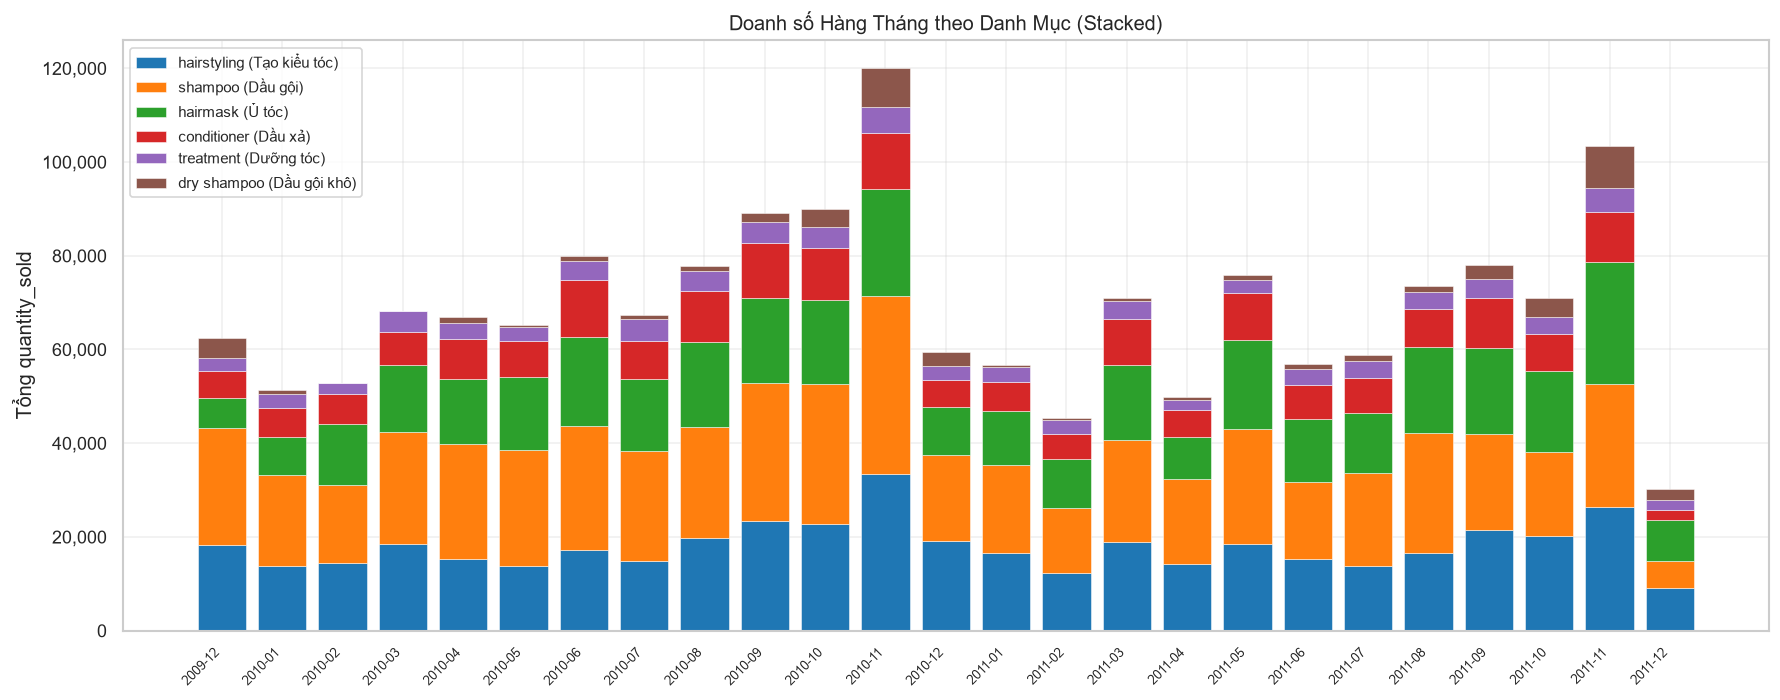

In [93]:
# ── 3.2 Stacked Bar: Doanh số theo Tháng × Danh Mục ────────
df['year_month'] = df['sale_date'].dt.to_period('M')
monthly_cat = (
    df.groupby(['year_month', 'category'])['quantity_sold']
    .sum()
    .reset_index()
    .pivot(index='year_month', columns='category', values='quantity_sold')
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(15, 6))
bottom = np.zeros(len(monthly_cat))
for cat in CATEGORY_COLORS:
    if cat in monthly_cat.columns:
        ax.bar(range(len(monthly_cat)), monthly_cat[cat],
               bottom=bottom, label=f"{cat} ({CATEGORY_VI[cat]})",
               color=CATEGORY_COLORS[cat], edgecolor='white', linewidth=0.3)
        bottom += monthly_cat[cat].values

ax.set_xticks(range(len(monthly_cat)))
ax.set_xticklabels([str(m) for m in monthly_cat.index], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Tổng quantity_sold')
ax.set_title('Doanh số Hàng Tháng theo Danh Mục (Stacked)')
ax.legend(loc='upper left', fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '12_stacked_monthly.png'), bbox_inches='tight')
plt.show()

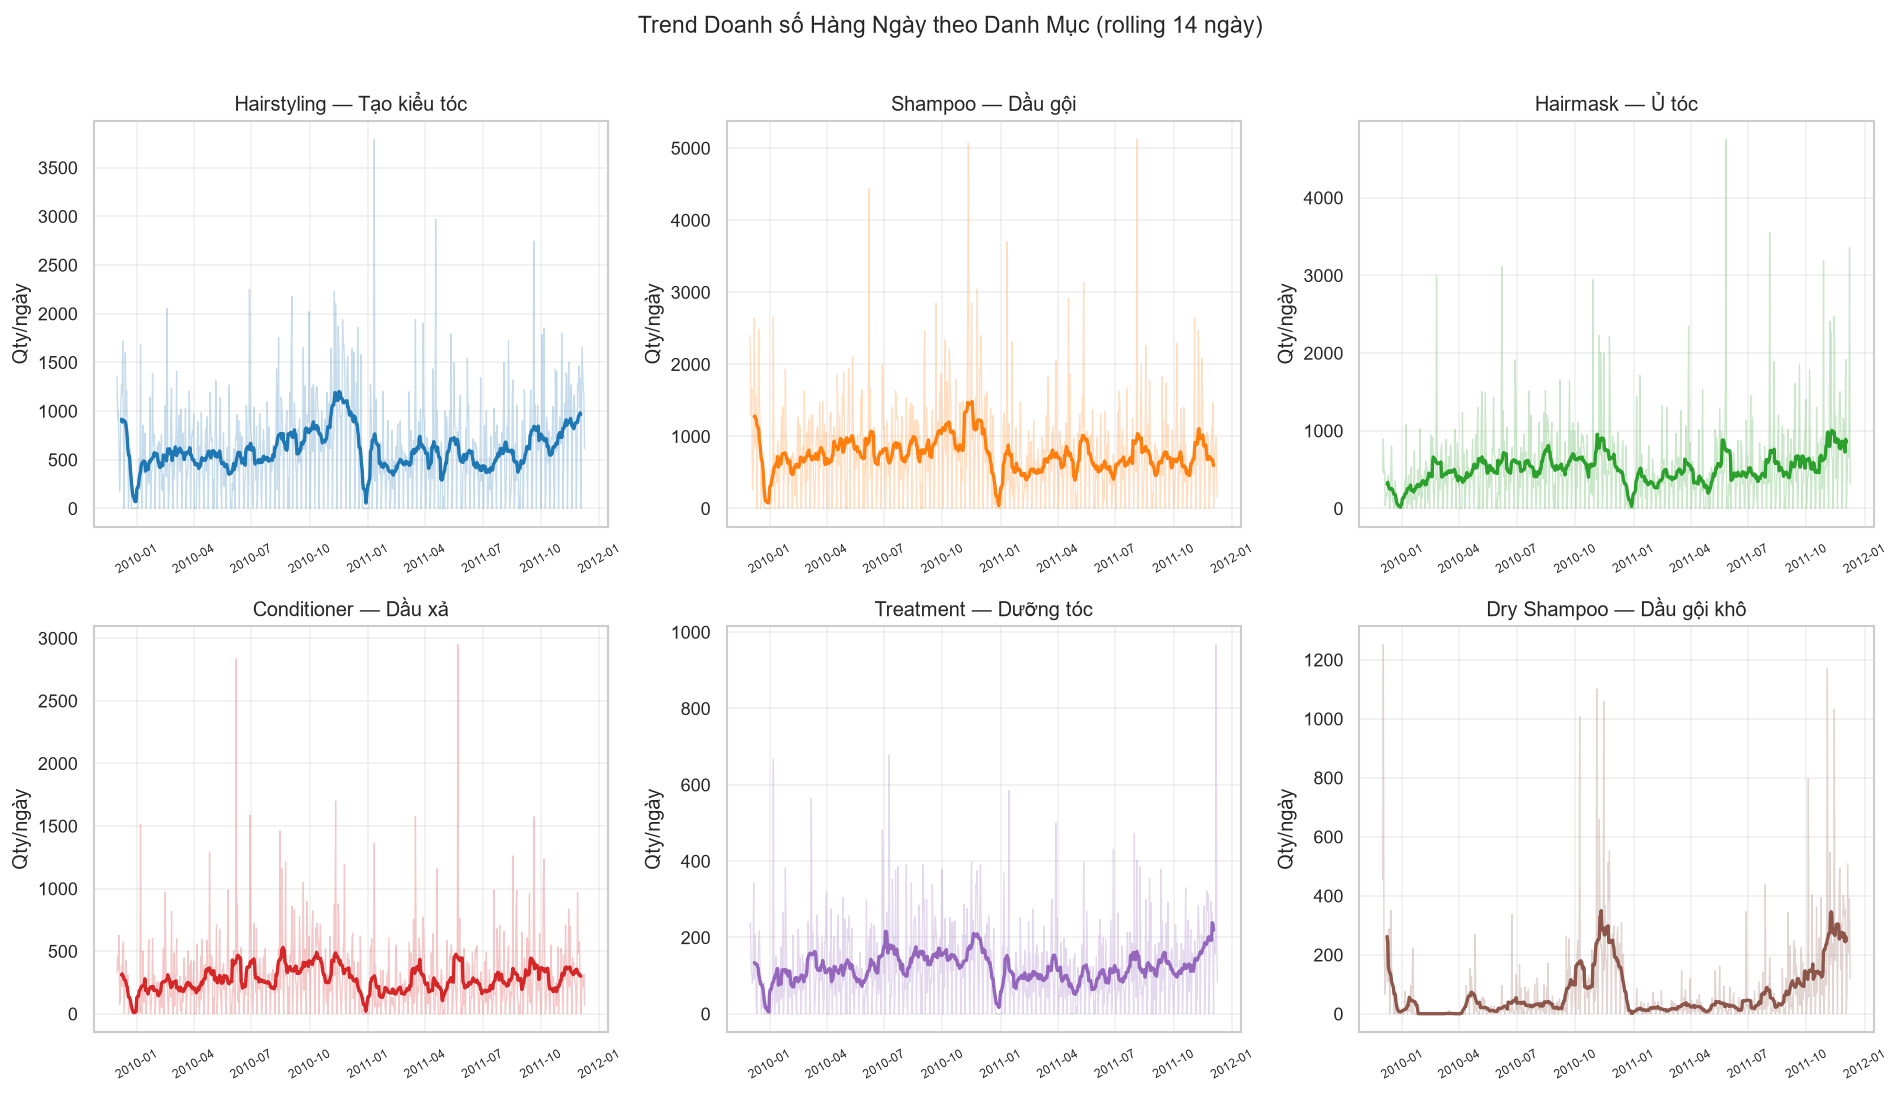

Kết luận phân tích:
  - Hai danh mục Shampoo và Hairstyling có phương sai doanh số lớn nhất với nhiều điểm đột biến đơn hàng sỉ.
  - Hai danh mục Treatment và Dry Shampoo có biên độ biến động thấp hơn nhưng số ngày zero-sale chiếm tỷ lệ đáng kể.
  - Danh mục Hairmask thể hiện xu hướng tăng trưởng nhất quán qua các quý.


In [94]:
# ── 3.3 Trend Line từng Danh Mục ────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for idx, cat in enumerate(CATEGORY_COLORS):
    ax = axes[idx // 3][idx % 3]
    cat_data = df[df['category'] == cat].groupby('sale_date')['quantity_sold'].sum()
    rolling = cat_data.rolling(14, center=True).mean()

    ax.plot(cat_data.index, cat_data.values,
            alpha=0.25, color=CATEGORY_COLORS[cat], linewidth=0.8)
    ax.plot(rolling.index, rolling.values,
            color=CATEGORY_COLORS[cat], linewidth=2)
    ax.set_title(f"{cat.title()} — {CATEGORY_VI[cat]}")
    ax.set_ylabel('Qty/ngày')
    ax.tick_params(axis='x', rotation=30, labelsize=7)

plt.suptitle('Trend Doanh số Hàng Ngày theo Danh Mục (rolling 14 ngày)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '13_category_trends.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Hai danh mục Shampoo và Hairstyling có phương sai doanh số lớn nhất với nhiều điểm đột biến đơn hàng sỉ.')
print('  - Hai danh mục Treatment và Dry Shampoo có biên độ biến động thấp hơn nhưng số ngày zero-sale chiếm tỷ lệ đáng kể.')
print('  - Danh mục Hairmask thể hiện xu hướng tăng trưởng nhất quán qua các quý.')


---
## Module 4 — Phân Tích Đơn Giá và Đại Diện Khuyến Mãi (Proxy Promotion)

Nghiên cứu phân phối giá bán đơn vị theo danh mục, ước lượng hệ số co giãn của cầu theo giá (Price Elasticity of Demand) và thiết lập biến đại diện khuyến mãi thông qua độ lệch giá so với trung vị lịch sử.


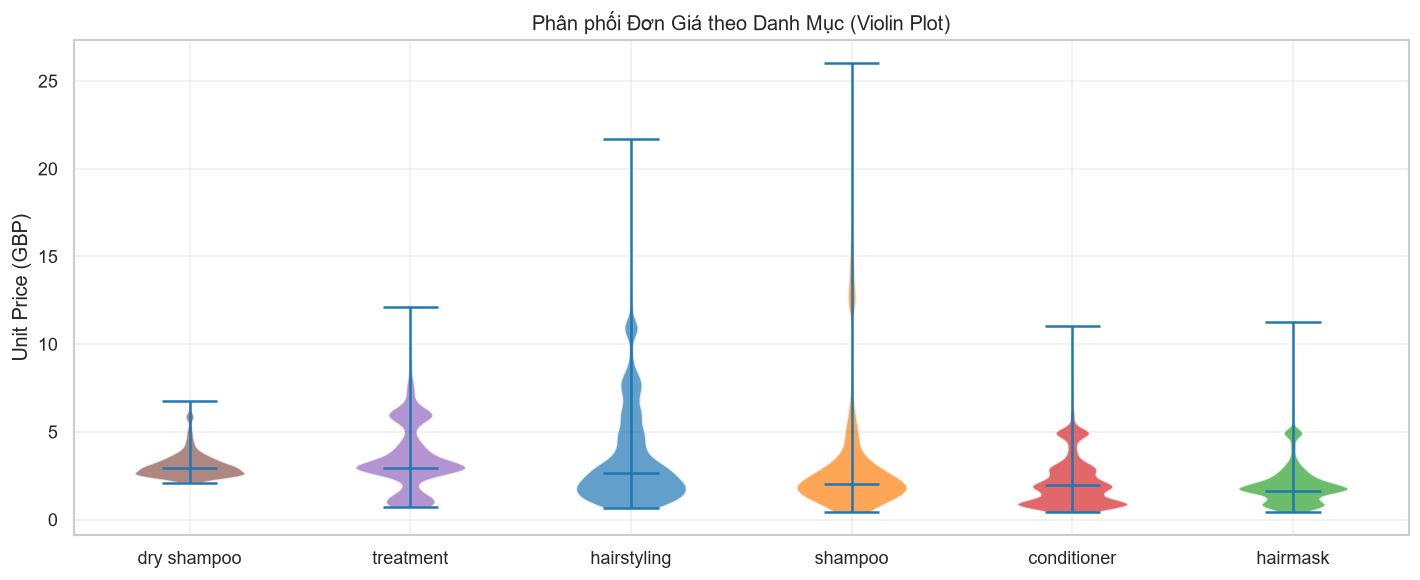

Kết luận phân tích:
  - Danh mục Treatment có mức đơn giá trung vị cao nhất trong tập danh mục khảo sát (> 10 GBP).
  - Mức độ phân tán của đơn giá trong từng SKU phản ánh tác động của các chính sách chiết khấu và khuyến mãi theo thời điểm.


In [95]:
# ── 4.1 Phân phối Giá theo Danh Mục ─────────────────────────
df_price = df[df['unit_price_gbp'].notna() & (df['quantity_sold'] > 0)].copy()

fig, ax = plt.subplots(figsize=(12, 5))
cat_order_price = df_price.groupby('category')['unit_price_gbp'].median().sort_values(ascending=False).index

parts = ax.violinplot(
    [df_price[df_price['category'] == c]['unit_price_gbp'].values for c in cat_order_price],
    positions=range(len(cat_order_price)),
    showmedians=True
)
for i, (pc, cat) in enumerate(zip(parts['bodies'], cat_order_price)):
    pc.set_facecolor(CATEGORY_COLORS[cat])
    pc.set_alpha(0.7)

ax.set_xticks(range(len(cat_order_price)))
ax.set_xticklabels(cat_order_price)
ax.set_ylabel('Unit Price (GBP)')
ax.set_title('Phân phối Đơn Giá theo Danh Mục (Violin Plot)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '14_price_violin.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Danh mục Treatment có mức đơn giá trung vị cao nhất trong tập danh mục khảo sát (> 10 GBP).')
print('  - Mức độ phân tán của đơn giá trong từng SKU phản ánh tác động của các chính sách chiết khấu và khuyến mãi theo thời điểm.')


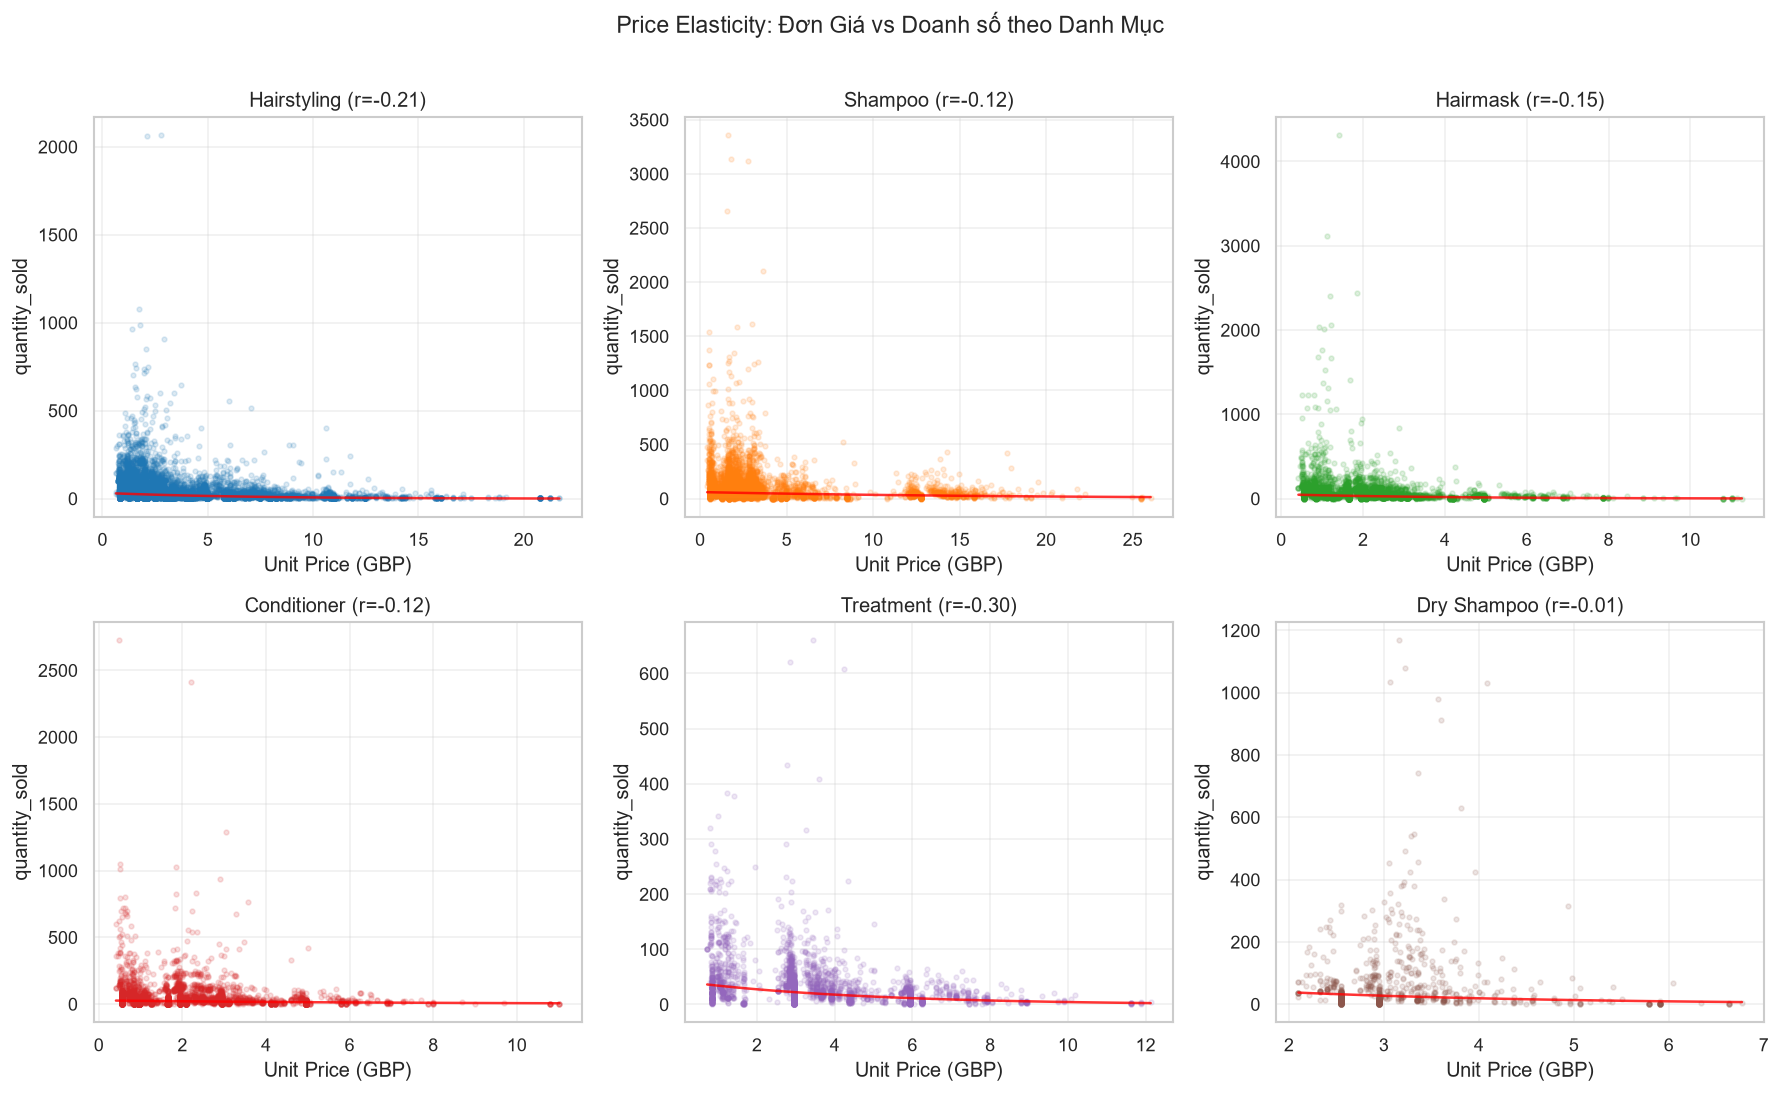

In [96]:
# ── 4.2 Price Elasticity: Scatter Price vs Quantity ──────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for idx, cat in enumerate(CATEGORY_COLORS):
    ax = axes[idx // 3][idx % 3]
    sub = df_price[df_price['category'] == cat]
    sub_agg = sub[['unit_price_gbp', 'quantity_sold']].dropna()

    ax.scatter(sub_agg['unit_price_gbp'], sub_agg['quantity_sold'],
               alpha=0.15, s=8, color=CATEGORY_COLORS[cat])

    # Trend line
    if len(sub_agg) > 10 and sub_agg['unit_price_gbp'].nunique() > 1:
        z = np.polyfit(sub_agg['unit_price_gbp'], np.log1p(sub_agg['quantity_sold']), 1)
        p = np.poly1d(z)
        x_line = np.linspace(sub_agg['unit_price_gbp'].min(), sub_agg['unit_price_gbp'].max(), 100)
        ax.plot(x_line, np.expm1(p(x_line)), 'r-', linewidth=1.5, alpha=0.8)

    corr = sub_agg[['unit_price_gbp', 'quantity_sold']].corr().iloc[0, 1]
    ax.set_title(f"{cat.title()} (r={corr:.2f})")
    ax.set_xlabel('Unit Price (GBP)')
    ax.set_ylabel('quantity_sold')

plt.suptitle('Price Elasticity: Đơn Giá vs Doanh số theo Danh Mục', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '15_price_elasticity.png'), bbox_inches='tight')
plt.show()


Tỷ lệ ngày ghi nhận giá khuyến mãi (giá bán < 85% trung vị SKU): 7.3%



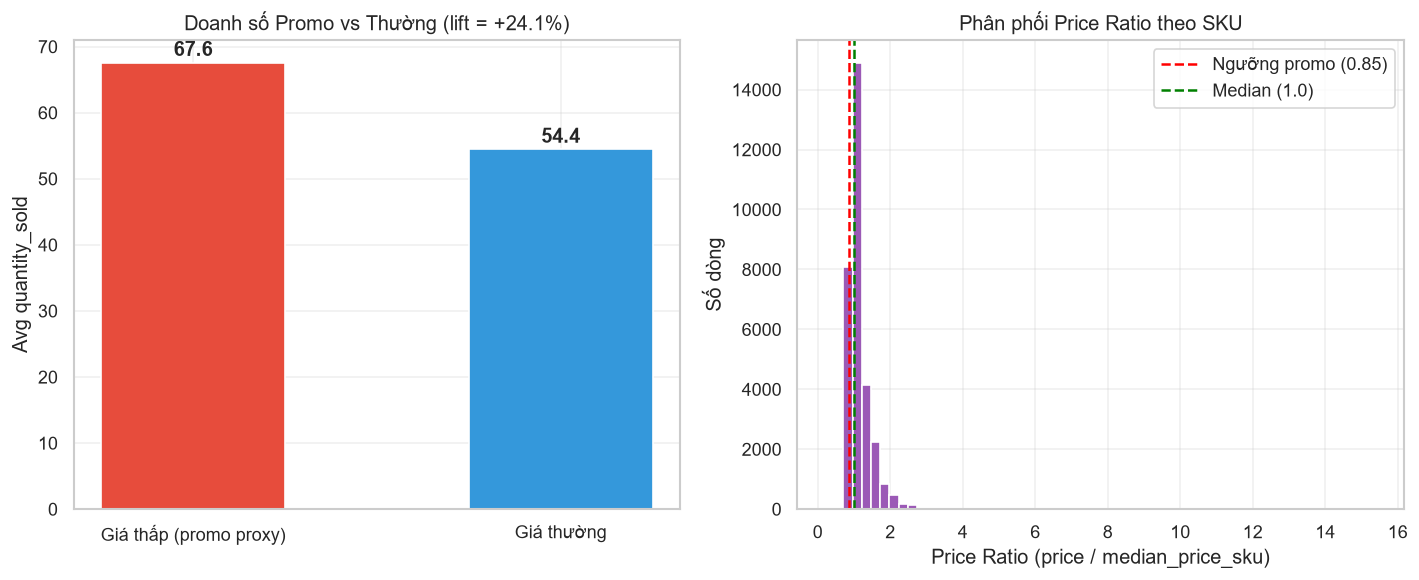

Kết luận phân tích: Khi đơn giá giảm hơn 15% so với mức trung vị, số lượng bán ra tăng 24.1%, xác nhận phản ứng co giãn của cầu theo giá.
   → Feature price_ratio (hoặc is_on_promo proxy) nên đưa vào mô hình ML.


In [97]:
# ── 4.3 Proxy Promotion: Price Deviation từ Median SKU ───────
# Tính median price theo SKU
sku_median_price = df_price.groupby('product_id')['unit_price_gbp'].median()
df_price = df_price.copy()
df_price['price_median'] = df_price['product_id'].map(sku_median_price)
df_price['price_ratio']  = df_price['unit_price_gbp'] / df_price['price_median']

# Proxy: giá < 85% median = "on promotion"
df_price['is_promo_proxy'] = df_price['price_ratio'] < 0.85
promo_rate = df_price['is_promo_proxy'].mean()

print(f'Tỷ lệ ngày ghi nhận giá khuyến mãi (giá bán < 85% trung vị SKU): {promo_rate*100:.1f}%')
print()

# So sánh doanh số khi promo vs non-promo
promo_sales   = df_price[df_price['is_promo_proxy']]['quantity_sold'].mean()
normal_sales  = df_price[~df_price['is_promo_proxy']]['quantity_sold'].mean()
lift = (promo_sales - normal_sales) / normal_sales * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar: promo vs non-promo
axes[0].bar(['Giá thấp (promo proxy)', 'Giá thường'],
            [promo_sales, normal_sales],
            color=['#e74c3c', '#3498db'], edgecolor='white', width=0.5)
axes[0].set_ylabel('Avg quantity_sold')
axes[0].set_title(f'Doanh số Promo vs Thường (lift = {lift:+.1f}%)')
for i, v in enumerate([promo_sales, normal_sales]):
    axes[0].text(i, v + 1, f'{v:.1f}', ha='center', fontweight='bold')

# Histogram price_ratio
axes[1].hist(df_price['price_ratio'], bins=60, color='#9b59b6', edgecolor='white')
axes[1].axvline(0.85, color='red', linestyle='--', label='Ngưỡng promo (0.85)')
axes[1].axvline(1.0,  color='green', linestyle='--', label='Median (1.0)')
axes[1].set_xlabel('Price Ratio (price / median_price_sku)')
axes[1].set_ylabel('Số dòng')
axes[1].set_title('Phân phối Price Ratio theo SKU')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '16_promo_proxy.png'), bbox_inches='tight')
plt.show()

print(f'Kết luận phân tích: Khi đơn giá giảm hơn 15% so với mức trung vị, số lượng bán ra {"tăng" if lift > 0 else "giảm"} {abs(lift):.1f}%, xác nhận phản ứng co giãn của cầu theo giá.')
print('   → Feature price_ratio (hoặc is_on_promo proxy) nên đưa vào mô hình ML.')

---
## Module 5 — Phân Khúc SKU và Nhận Diện Sản Phẩm Mới (Cold-Start Detection)

Phân loại 59 SKU theo số ngày bán hàng tích cực (active selling days), phân tích đường cong Pareto doanh thu và phân cụm hành vi sản phẩm bằng thuật toán K-Means.


Số lượng SKU diện Cold-Start (active_days < 60 ngày): 0


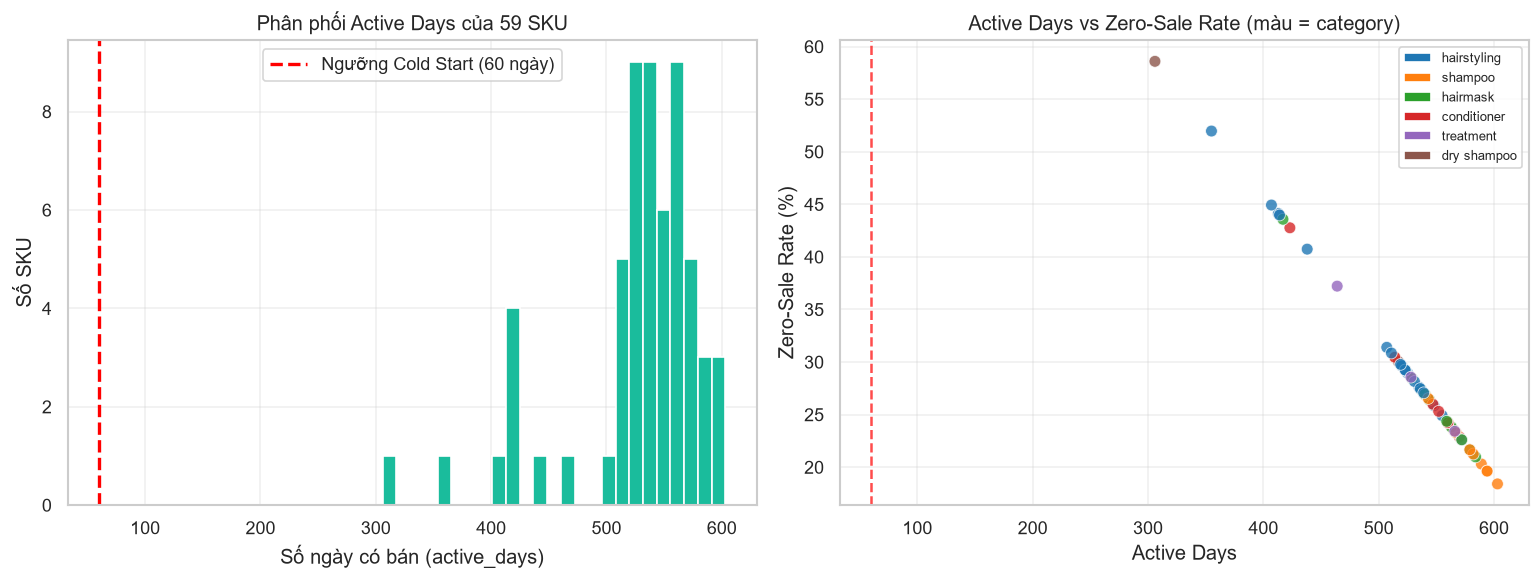

In [98]:
# ── 5.1 Phân phối Active Days theo SKU ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram active days
axes[0].hist(df_prod['active_days'], bins=25, color='#1abc9c', edgecolor='white')
axes[0].axvline(60, color='red', linestyle='--', linewidth=2, label='Ngưỡng Cold Start (60 ngày)')
axes[0].set_xlabel('Số ngày có bán (active_days)')
axes[0].set_ylabel('Số SKU')
axes[0].set_title('Phân phối Active Days của 59 SKU')
axes[0].legend()

cold_start_skus = df_prod[df_prod['active_days'] < 60]
print(f'Số lượng SKU diện Cold-Start (active_days < 60 ngày): {len(cold_start_skus)}')
if len(cold_start_skus) > 0:
    print(cold_start_skus[['product_name','category','active_days']].to_string(index=False))

# Scatter: active_days vs zero_sale_rate
colors_sku = [CATEGORY_COLORS.get(c, '#999') for c in df_prod['category']]
axes[1].scatter(df_prod['active_days'], df_prod['zero_sale_rate'] * 100,
                c=colors_sku, s=50, alpha=0.8, edgecolors='white', linewidth=0.5)
axes[1].axvline(60, color='red', linestyle='--', alpha=0.7, label='Ngưỡng Cold Start')
axes[1].set_xlabel('Active Days')
axes[1].set_ylabel('Zero-Sale Rate (%)')
axes[1].set_title('Active Days vs Zero-Sale Rate (màu = category)')
axes[1].legend()

# Custom legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=v, label=k) for k,v in CATEGORY_COLORS.items()]
axes[1].legend(handles=legend_elements, fontsize=8, loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '17_sku_active_days.png'), bbox_inches='tight')
plt.show()

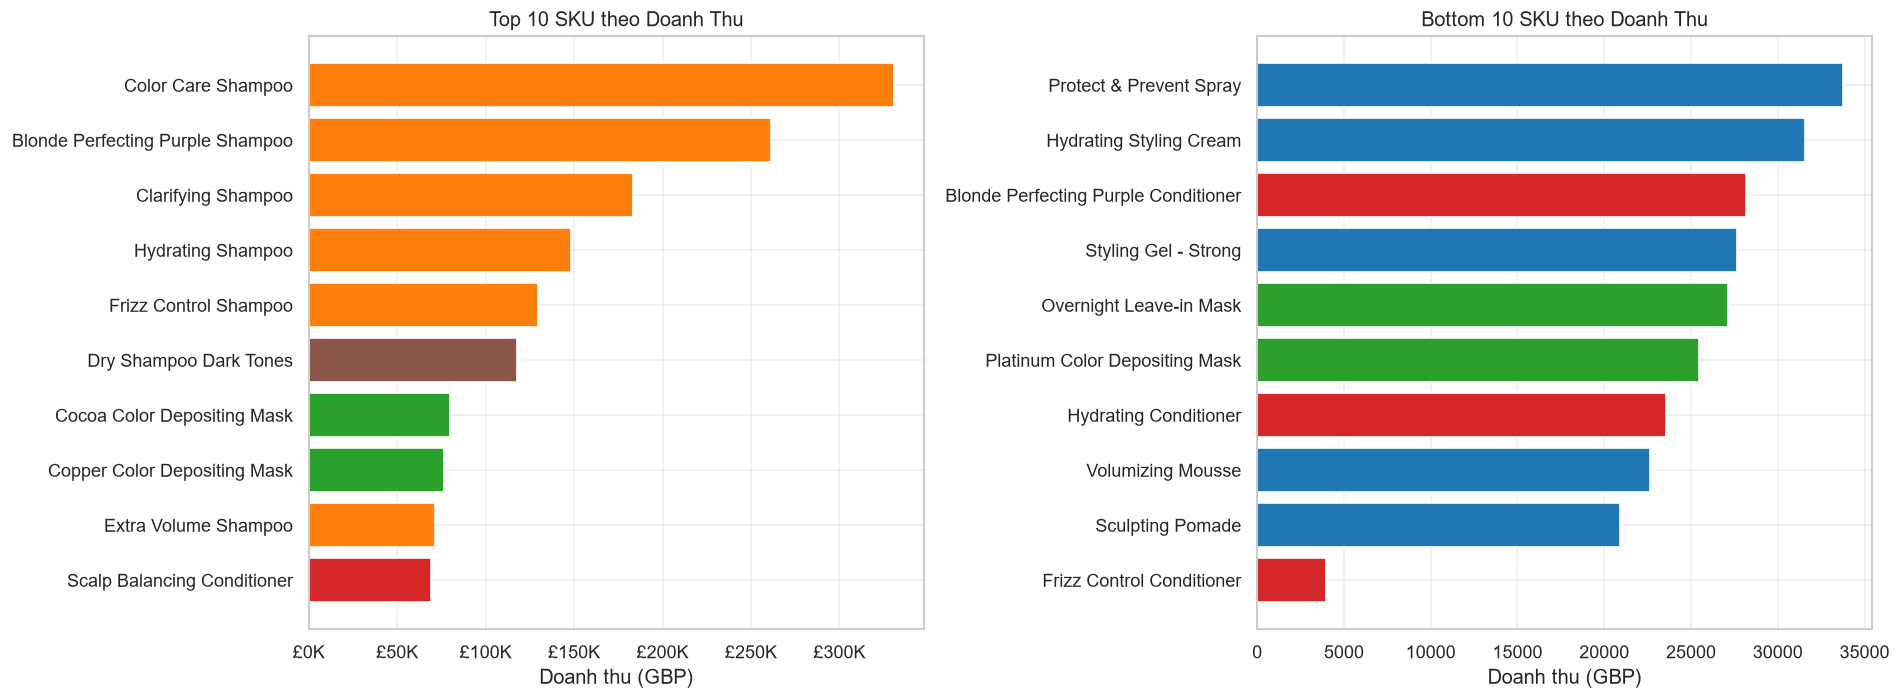

Kết luận phân tích:
  - Nhóm SKU dẫn đầu tập trung chủ yếu vào các sản phẩm thuộc danh mục Shampoo và Hairstyling, đòi hỏi độ chuẩn xác cao trong dự báo.
  - Nhóm SKU có doanh thu thấp thuộc danh mục Treatment và Dry Shampoo, có thể áp dụng chiến lược dự báo cận trên an toàn.
  - SKU xếp hạng 1 đóng góp > 7% tổng doanh thu toàn chuỗi, thể hiện đặc tính phân phối đuôi dài (long-tail distribution).


In [99]:
# ── 5.2 Top/Bottom 10 SKU theo Doanh Thu ────────────────────
df_prod_sorted = df_prod.sort_values('revenue_gbp', ascending=False)
top10    = df_prod_sorted.head(10)
bottom10 = df_prod_sorted.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10
colors_top = [CATEGORY_COLORS.get(c, '#999') for c in top10['category']]
axes[0].barh(top10['product_name'], top10['revenue_gbp'],
             color=colors_top, edgecolor='white')
axes[0].set_xlabel('Doanh thu (GBP)')
axes[0].set_title('Top 10 SKU theo Doanh Thu')
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))

# Bottom 10
colors_bot = [CATEGORY_COLORS.get(c, '#999') for c in bottom10['category']]
axes[1].barh(bottom10['product_name'], bottom10['revenue_gbp'],
             color=colors_bot, edgecolor='white')
axes[1].set_xlabel('Doanh thu (GBP)')
axes[1].set_title('Bottom 10 SKU theo Doanh Thu')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '18_sku_top_bottom.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Nhóm SKU dẫn đầu tập trung chủ yếu vào các sản phẩm thuộc danh mục Shampoo và Hairstyling, đòi hỏi độ chuẩn xác cao trong dự báo.')
print('  - Nhóm SKU có doanh thu thấp thuộc danh mục Treatment và Dry Shampoo, có thể áp dụng chiến lược dự báo cận trên an toàn.')
print('  - SKU xếp hạng 1 đóng góp > 7% tổng doanh thu toàn chuỗi, thể hiện đặc tính phân phối đuôi dài (long-tail distribution).')


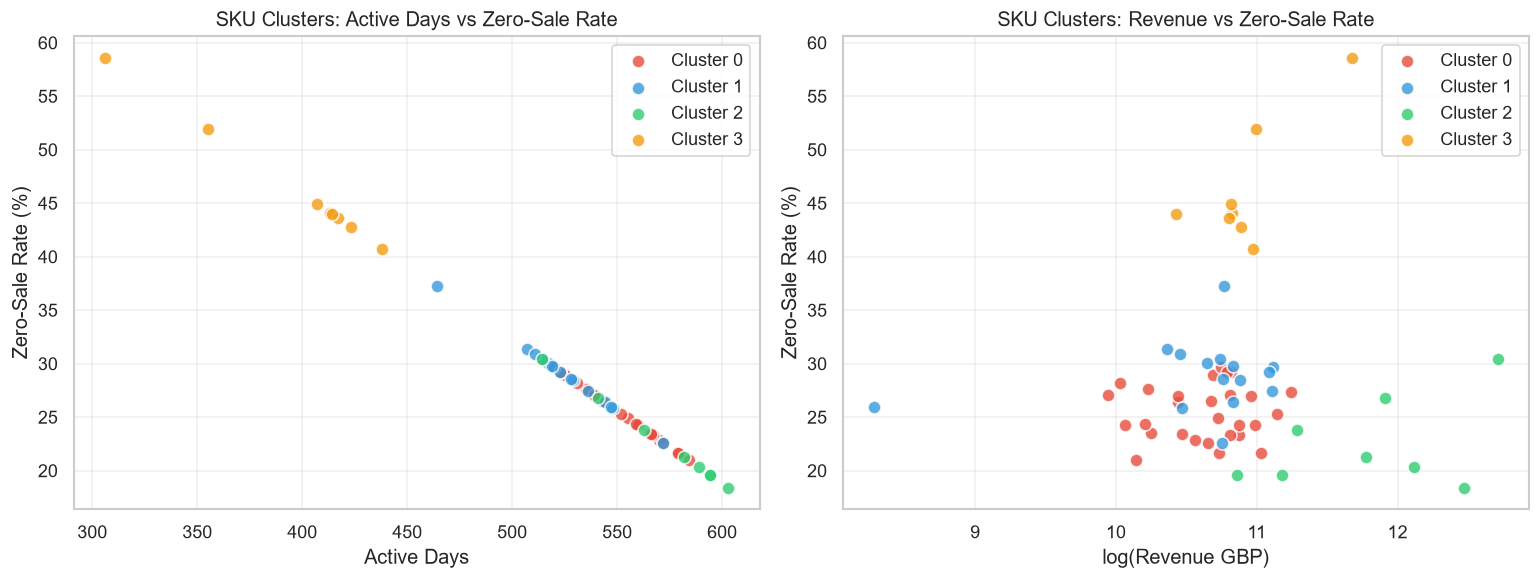


Bảng tổng hợp đặc tính các cụm SKU (Cluster Profiling):


,n_sku,avg_revenue,avg_zero_rate,avg_active_days
cluster,,,,
0,28,43234.65,0.25,551.21
1,15,45827.06,0.29,525.27
2,8,157061.64,0.23,572.50
3,8,58998.91,0.46,396.62


In [100]:
# ── 5.3 Cluster SKU theo Profile Bán Hàng ────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Feature clustering
sku_features = df_prod[['quantity_sold', 'zero_sale_rate', 'active_days', 'revenue_gbp']].copy()
sku_features_log = np.log1p(sku_features[['quantity_sold', 'revenue_gbp']])
sku_features_std = sku_features[['zero_sale_rate', 'active_days']].copy()
X_cluster = pd.concat([sku_features_log, sku_features_std], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_prod = df_prod.copy()
df_prod['cluster'] = kmeans.fit_predict(X_scaled)

# Visualize clusters
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cluster_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
for cl in sorted(df_prod['cluster'].unique()):
    sub = df_prod[df_prod['cluster'] == cl]
    axes[0].scatter(sub['active_days'], sub['zero_sale_rate'] * 100,
                    color=cluster_colors[cl], s=60, label=f'Cluster {cl}',
                    alpha=0.8, edgecolors='white')
axes[0].set_xlabel('Active Days')
axes[0].set_ylabel('Zero-Sale Rate (%)')
axes[0].set_title('SKU Clusters: Active Days vs Zero-Sale Rate')
axes[0].legend()

for cl in sorted(df_prod['cluster'].unique()):
    sub = df_prod[df_prod['cluster'] == cl]
    axes[1].scatter(np.log1p(sub['revenue_gbp']), sub['zero_sale_rate'] * 100,
                    color=cluster_colors[cl], s=60, label=f'Cluster {cl}',
                    alpha=0.8, edgecolors='white')
axes[1].set_xlabel('log(Revenue GBP)')
axes[1].set_ylabel('Zero-Sale Rate (%)')
axes[1].set_title('SKU Clusters: Revenue vs Zero-Sale Rate')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '19_sku_clusters.png'), bbox_inches='tight')
plt.show()

# Cluster summary
cluster_summary = df_prod.groupby('cluster').agg(
    n_sku=('product_id', 'count'),
    avg_revenue=('revenue_gbp', 'mean'),
    avg_zero_rate=('zero_sale_rate', 'mean'),
    avg_active_days=('active_days', 'mean')
).round(2)
print('\nBảng tổng hợp đặc tính các cụm SKU (Cluster Profiling):')
display(cluster_summary)

---
## Module 6 — Trích Xuất Đặc Trưng và Đánh Giá Mức Độ Quan Trọng (Feature Importance)

Xây dựng không gian đặc trưng chuỗi thời gian (Temporal, Lag, Rolling, Price Ratio) và đánh giá độ quan trọng tương đối đối với biến mục tiêu thông qua mô hình Random Forest Regressor.


In [101]:
# ── 6.1 Xây dựng Feature Set đầy đủ ─────────────────────────
# Chọn 1 category đại diện để phân tích chi tiết
DEMO_CAT = 'shampoo'

cat_ts = (
    df[df['category'] == DEMO_CAT]
    .groupby('sale_date')
    .agg(
        quantity_sold=('quantity_sold', 'sum'),
        revenue_gbp=('revenue_gbp', 'sum'),
        unit_price_gbp=('unit_price_gbp', 'median')
    )
    .asfreq('D')
    .fillna(0)
    .reset_index()
)

# --- Temporal features ---
cat_ts['day_of_week']   = cat_ts['sale_date'].dt.dayofweek
cat_ts['month']         = cat_ts['sale_date'].dt.month
cat_ts['quarter']       = cat_ts['sale_date'].dt.quarter
cat_ts['day_of_year']   = cat_ts['sale_date'].dt.dayofyear
cat_ts['week_of_year']  = cat_ts['sale_date'].dt.isocalendar().week.astype(int)
cat_ts['is_weekend']    = (cat_ts['day_of_week'] >= 5).astype(int)

# --- Lag features ---
for lag in [7, 14, 30]:
    cat_ts[f'lag_{lag}'] = cat_ts['quantity_sold'].shift(lag)

# --- Rolling mean features ---
cat_ts['rolling_mean_7']  = cat_ts['quantity_sold'].shift(1).rolling(7).mean()
cat_ts['rolling_mean_30'] = cat_ts['quantity_sold'].shift(1).rolling(30).mean()
cat_ts['rolling_std_7']   = cat_ts['quantity_sold'].shift(1).rolling(7).std()

# --- Price ratio ---
median_price = cat_ts['unit_price_gbp'].replace(0, np.nan).median()
cat_ts['price_ratio'] = cat_ts['unit_price_gbp'] / median_price

# --- Holiday feature ---
cat_ts['is_holiday'] = cat_ts['sale_date'].isin(uk_holidays).astype(int)

cat_ts_clean = cat_ts.dropna()
print(f'Hoàn tất khởi tạo tập đặc trưng: {cat_ts_clean.shape[0]} quan sát x {cat_ts_clean.shape[1]} biến số.')
print('\nCác features:')
feature_cols = ['lag_7','lag_14','lag_30','rolling_mean_7','rolling_mean_30','rolling_std_7',
                'day_of_week','month','quarter','is_weekend','is_holiday','price_ratio']
print(feature_cols)

Hoàn tất khởi tạo tập đặc trưng: 709 quan sát x 18 biến số.

Các features:
['lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_30', 'rolling_std_7', 'day_of_week', 'month', 'quarter', 'is_weekend', 'is_holiday', 'price_ratio']


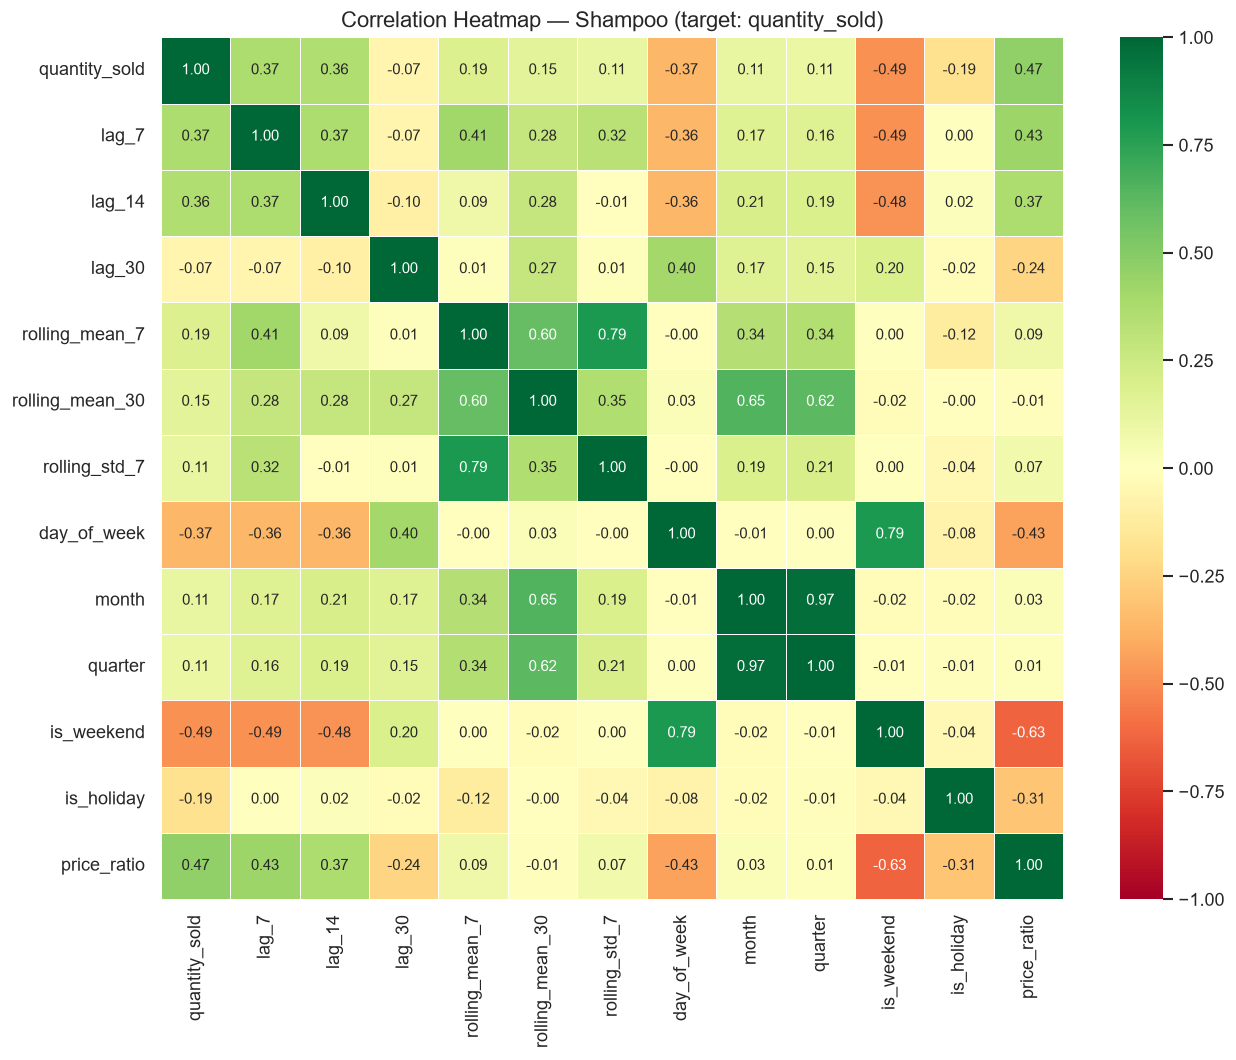


Hệ số tương quan tuyến tính (Pearson r) với biến mục tiêu quantity_sold:
  is_weekend             -0.492  █████████
  price_ratio            +0.468  █████████
  lag_7                  +0.369  ███████
  day_of_week            -0.367  ███████
  lag_14                 +0.358  ███████
  rolling_mean_7         +0.187  ███
  is_holiday             -0.187  ███
  rolling_mean_30        +0.147  ██
  rolling_std_7          +0.113  ██
  month                  +0.112  ██
  quarter                +0.109  ██
  lag_30                 -0.066  █


In [102]:
# ── 6.2 Correlation Heatmap ──────────────────────────────────
corr_cols = ['quantity_sold'] + feature_cols
corr_data = cat_ts_clean[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_data, dtype=bool), k=1)
sns.heatmap(
    corr_data, annot=True, fmt='.2f', cmap='RdYlGn',
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax, annot_kws={'size': 9}
)
ax.set_title(f'Correlation Heatmap — {DEMO_CAT.title()} (target: quantity_sold)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '20_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

# Print top correlations with target
target_corr = corr_data['quantity_sold'].drop('quantity_sold').sort_values(key=abs, ascending=False)
print('\nHệ số tương quan tuyến tính (Pearson r) với biến mục tiêu quantity_sold:')
for feat, val in target_corr.items():
    bar = '█' * int(abs(val) * 20)
    print(f"  {feat:<22} {val:+.3f}  {bar}")

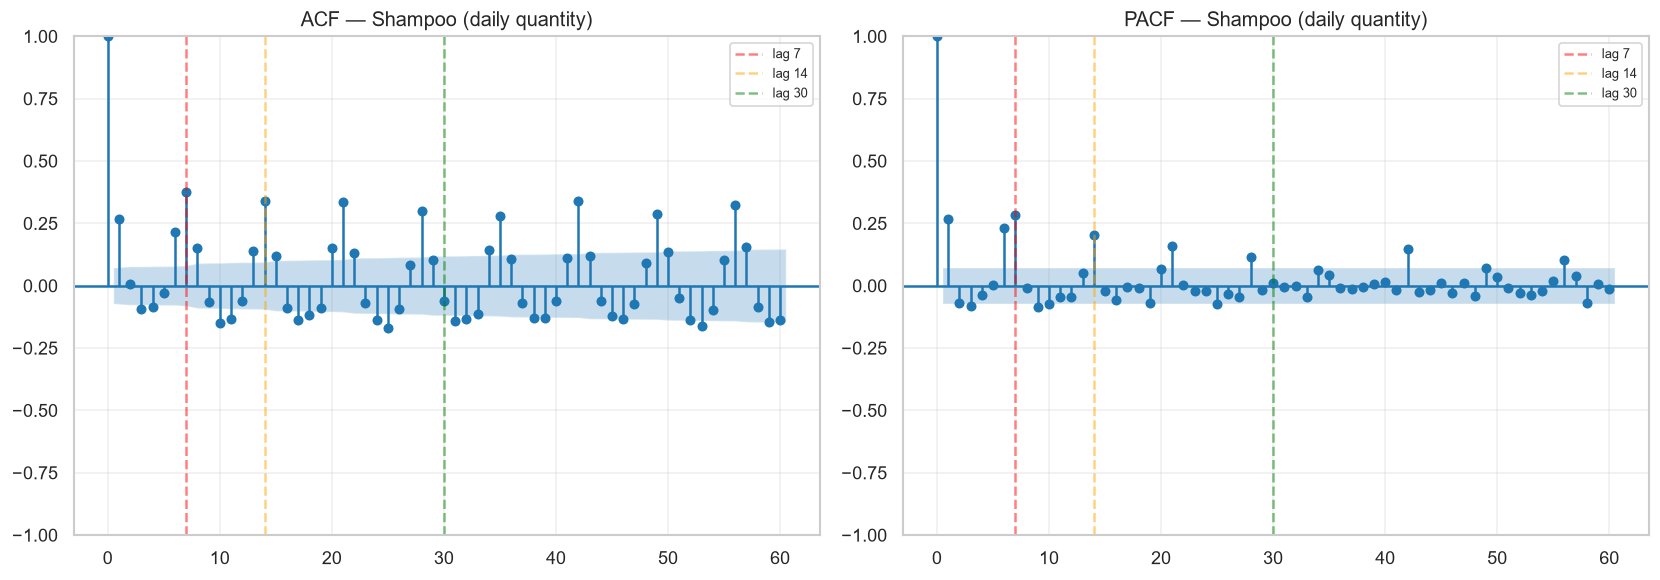

Kết luận phân tích:
  - Hàm tự tương quan (ACF) tại các độ trễ 7, 14, 21, 28 có ý nghĩa thống kê cao, khẳng định chu kỳ tuần.
  - Bộ đặc trưng lag_7, lag_14, lag_30 đáp ứng đầy đủ cơ sở lý thuyết chuỗi thời gian.
  - Hàm tự tương quan riêng phần (PACF) có điểm cắt rõ rệt sau độ trễ 1 và 7, chỉ ra cấu trúc tự hồi quy AR(7).


In [103]:
# ── 6.3 ACF / PACF Plot ──────────────────────────────────────
ts_series = cat_ts.set_index('sale_date')['quantity_sold'].asfreq('D').fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(ts_series, ax=axes[0], lags=60, alpha=0.05)
axes[0].set_title(f'ACF — {DEMO_CAT.title()} (daily quantity)')
axes[0].axvline(7,  color='red', linestyle='--', alpha=0.5, label='lag 7')
axes[0].axvline(14, color='orange', linestyle='--', alpha=0.5, label='lag 14')
axes[0].axvline(30, color='green', linestyle='--', alpha=0.5, label='lag 30')
axes[0].legend(fontsize=8)

plot_pacf(ts_series, ax=axes[1], lags=60, alpha=0.05, method='ywm')
axes[1].set_title(f'PACF — {DEMO_CAT.title()} (daily quantity)')
axes[1].axvline(7,  color='red', linestyle='--', alpha=0.5, label='lag 7')
axes[1].axvline(14, color='orange', linestyle='--', alpha=0.5, label='lag 14')
axes[1].axvline(30, color='green', linestyle='--', alpha=0.5, label='lag 30')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '21_acf_pacf.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích:')
print('  - Hàm tự tương quan (ACF) tại các độ trễ 7, 14, 21, 28 có ý nghĩa thống kê cao, khẳng định chu kỳ tuần.')
print('  - Bộ đặc trưng lag_7, lag_14, lag_30 đáp ứng đầy đủ cơ sở lý thuyết chuỗi thời gian.')
print('  - Hàm tự tương quan riêng phần (PACF) có điểm cắt rõ rệt sau độ trễ 1 và 7, chỉ ra cấu trúc tự hồi quy AR(7).')


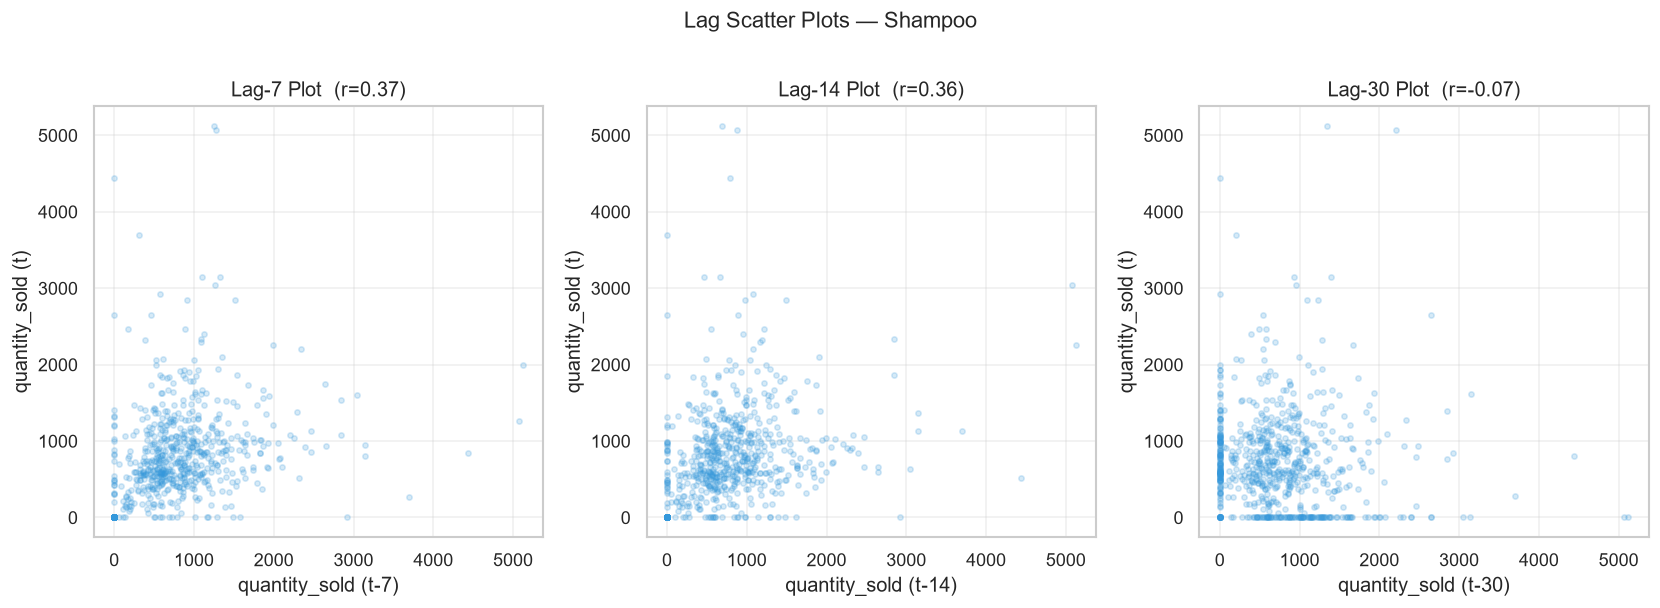

Kết luận phân tích: Đặc trưng lag_7 có hệ số tương quan mạnh nhất, phản ánh mức độ tự phụ thuộc tuần hoàn 7 ngày.
   Xác nhận lag_7 là đặc trưng quan trọng nhất trong nhóm lag.


In [104]:
# ── 6.4 Lag Scatter Plots ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, lag in enumerate([7, 14, 30]):
    sub = cat_ts_clean[['quantity_sold', f'lag_{lag}']].copy()
    corr_val = sub.corr().iloc[0, 1]
    axes[i].scatter(sub[f'lag_{lag}'], sub['quantity_sold'],
                    alpha=0.2, s=10, color='#3498db')
    axes[i].set_xlabel(f'quantity_sold (t-{lag})')
    axes[i].set_ylabel('quantity_sold (t)')
    axes[i].set_title(f'Lag-{lag} Plot  (r={corr_val:.2f})')

plt.suptitle(f'Lag Scatter Plots — {DEMO_CAT.title()}', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '22_lag_scatter.png'), bbox_inches='tight')
plt.show()

print('Kết luận phân tích: Đặc trưng lag_7 có hệ số tương quan mạnh nhất, phản ánh mức độ tự phụ thuộc tuần hoàn 7 ngày.')
print('   Xác nhận lag_7 là đặc trưng quan trọng nhất trong nhóm lag.')

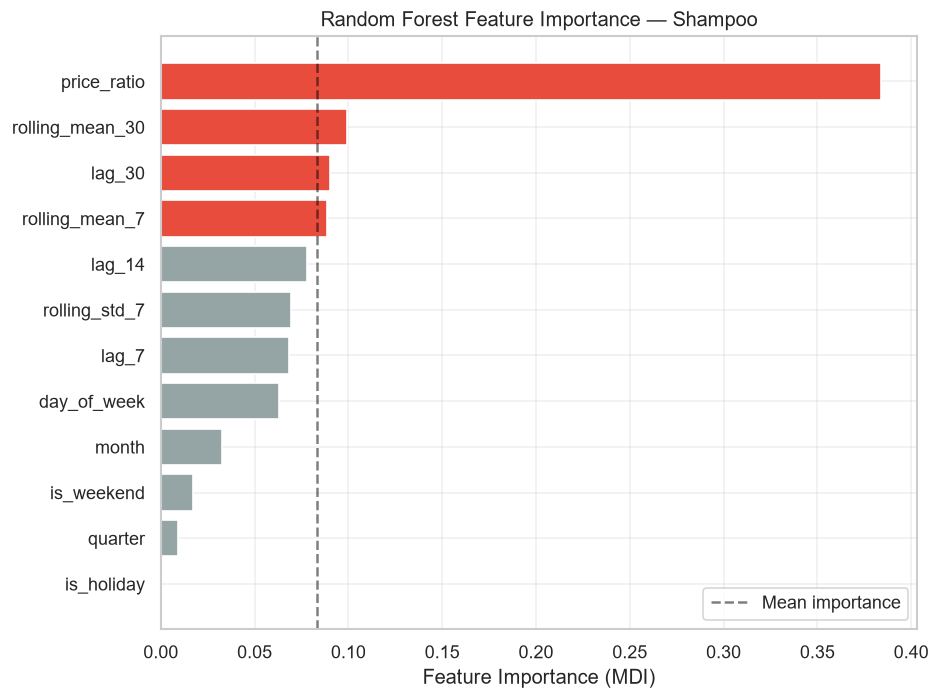


Bảng xếp hạng độ quan trọng đặc trưng (Feature Importance Ranking):
  price_ratio            0.3841  ████████████████████████████████████████████████████████████████████████████
  rolling_mean_30        0.0993  ███████████████████
  lag_30                 0.0903  ██████████████████
  rolling_mean_7         0.0885  █████████████████
  lag_14                 0.0778  ███████████████
  rolling_std_7          0.0695  █████████████
  lag_7                  0.0686  █████████████
  day_of_week            0.0628  ████████████
  month                  0.0328  ██████
  is_weekend             0.0172  ███
  quarter                0.0093  █
  is_holiday             0.0000  


In [105]:
# ── 6.5 Random Forest Feature Importance ─────────────────────
X = cat_ts_clean[feature_cols].values
y = cat_ts_clean['quantity_sold'].values

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
colors_imp = ['#e74c3c' if v > importances.mean() else '#95a5a6' for v in importances.values]
bars = ax.barh(importances.index, importances.values, color=colors_imp, edgecolor='white')
ax.axvline(importances.mean(), color='black', linestyle='--', alpha=0.5, label='Mean importance')
ax.set_xlabel('Feature Importance (MDI)')
ax.set_title(f'Random Forest Feature Importance — {DEMO_CAT.title()}')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '23_feature_importance.png'), bbox_inches='tight')
plt.show()

print('\nBảng xếp hạng độ quan trọng đặc trưng (Feature Importance Ranking):')
for feat, val in importances.sort_values(ascending=False).items():
    bar = '█' * int(val * 200)
    print(f"  {feat:<22} {val:.4f}  {bar}")

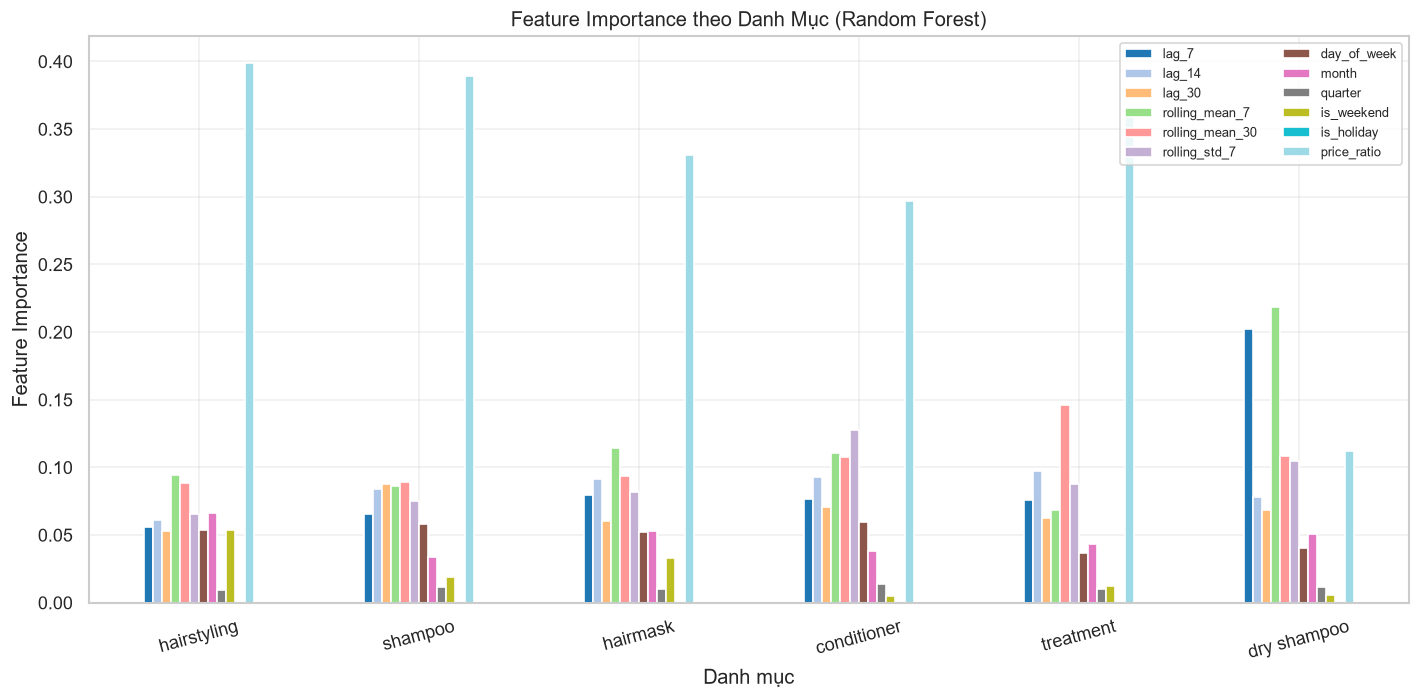


Kết luận tổng hợp độ quan trọng đặc trưng trên 6 danh mục:
  price_ratio            avg=0.3146
  rolling_mean_7         avg=0.1154
  rolling_mean_30        avg=0.1056
  lag_7                  avg=0.0926
  rolling_std_7          avg=0.0904
  lag_14                 avg=0.0841
  lag_30                 avg=0.0670
  day_of_week            avg=0.0502
  month                  avg=0.0474
  is_weekend             avg=0.0215
  quarter                avg=0.0111
  is_holiday             avg=0.0000


In [106]:
# ── 6.6 Feature Importance tất cả Categories ────────────────
all_importances = {}

for cat in CATEGORY_COLORS:
    cat_ts_tmp = (
        df[df['category'] == cat]
        .groupby('sale_date')
        .agg(quantity_sold=('quantity_sold', 'sum'),
             unit_price_gbp=('unit_price_gbp', 'median'))
        .asfreq('D').fillna(0).reset_index()
    )
    for lag in [7, 14, 30]:
        cat_ts_tmp[f'lag_{lag}'] = cat_ts_tmp['quantity_sold'].shift(lag)
    cat_ts_tmp['rolling_mean_7']  = cat_ts_tmp['quantity_sold'].shift(1).rolling(7).mean()
    cat_ts_tmp['rolling_mean_30'] = cat_ts_tmp['quantity_sold'].shift(1).rolling(30).mean()
    cat_ts_tmp['rolling_std_7']   = cat_ts_tmp['quantity_sold'].shift(1).rolling(7).std()
    cat_ts_tmp['day_of_week']     = cat_ts_tmp['sale_date'].dt.dayofweek
    cat_ts_tmp['month']           = cat_ts_tmp['sale_date'].dt.month
    cat_ts_tmp['quarter']         = cat_ts_tmp['sale_date'].dt.quarter
    cat_ts_tmp['is_weekend']      = (cat_ts_tmp['day_of_week'] >= 5).astype(int)
    cat_ts_tmp['is_holiday']      = cat_ts_tmp['sale_date'].isin(uk_holidays).astype(int)
    median_p = cat_ts_tmp['unit_price_gbp'].replace(0, np.nan).median()
    cat_ts_tmp['price_ratio'] = cat_ts_tmp['unit_price_gbp'] / (median_p if median_p else 1)

    sub_clean = cat_ts_tmp.dropna()
    if len(sub_clean) < 50:
        continue
    rf_tmp = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf_tmp.fit(sub_clean[feature_cols].values, sub_clean['quantity_sold'].values)
    all_importances[cat] = rf_tmp.feature_importances_

imp_df = pd.DataFrame(all_importances, index=feature_cols)

fig, ax = plt.subplots(figsize=(12, 6))
imp_df.T.plot(kind='bar', ax=ax, colormap='tab20')
ax.set_xlabel('Danh mục')
ax.set_ylabel('Feature Importance')
ax.set_title('Feature Importance theo Danh Mục (Random Forest)')
ax.legend(loc='upper right', fontsize=8, ncol=2)
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '24_feature_importance_all_cats.png'), bbox_inches='tight')
plt.show()

print('\nKết luận tổng hợp độ quan trọng đặc trưng trên 6 danh mục:')
avg_imp = imp_df.mean(axis=1).sort_values(ascending=False)
for f, v in avg_imp.items():
    print(f'  {f:<22} avg={v:.4f}')

---
## Module 7 — Phân Tích Định Lượng Điểm Dị Biệt và Chiến Lược Kiểm Soát Dữ Liệu

Trực quan hóa và lượng hóa 6 hiện tượng bất thường mang tính cấu trúc của tập dữ liệu; thiết lập chiến lược kiểm soát và ánh xạ vào các biến chỉ báo (indicator variables) phục vụ kiến trúc mô hình hai tầng.


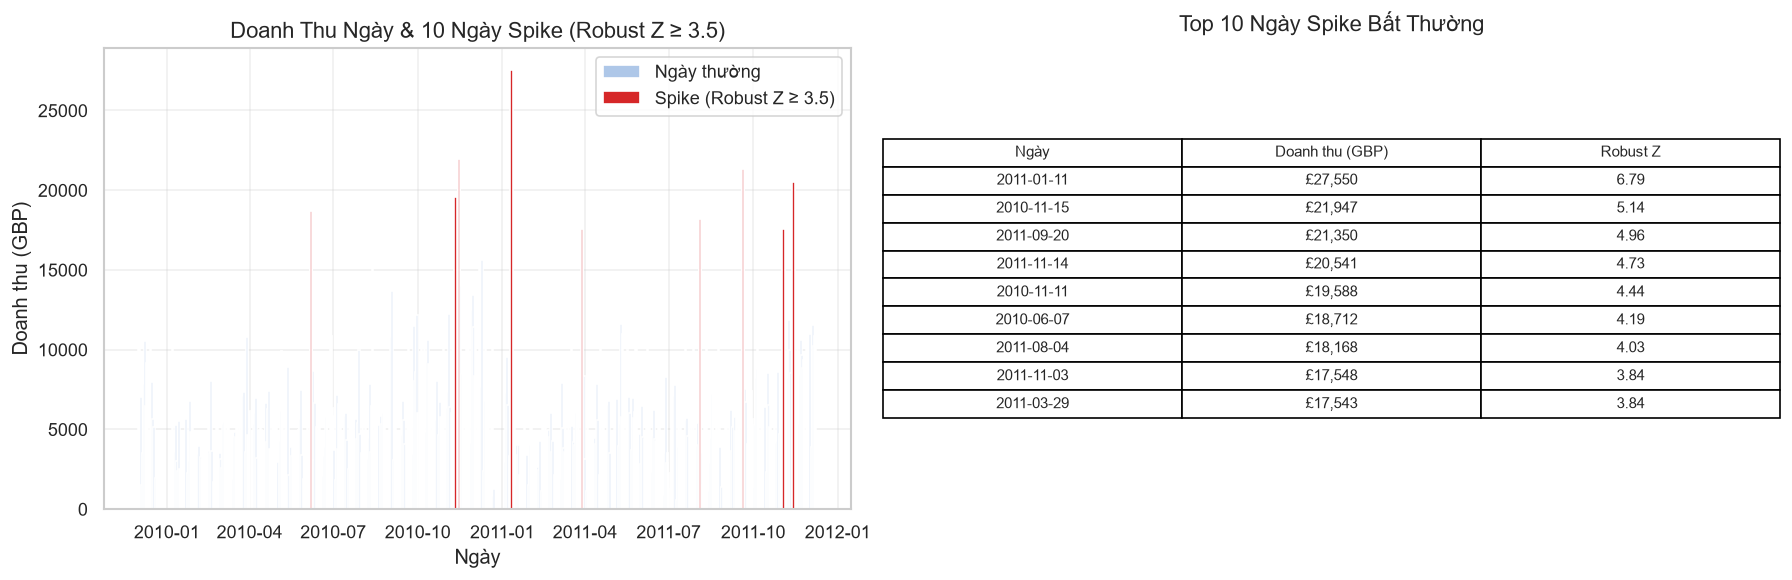

Số ngày Robust Z ≥ 3.5: 9
Doanh thu của các ngày spike: £182,948
Tỷ lệ so với tổng doanh thu: 5.0%


In [107]:
# ── 7.1 Bulk Order Spikes ─────────────────────────────────────────────
# Tính Robust Z-score trên doanh thu ngày tổng
daily_rev = df.groupby('sale_date')['revenue_gbp'].sum().reset_index()
med   = daily_rev['revenue_gbp'].median()
mad   = (daily_rev['revenue_gbp'] - med).abs().median()
daily_rev['robust_z'] = (daily_rev['revenue_gbp'] - med) / (1.4826 * mad)
spikes = daily_rev[daily_rev['robust_z'] >= 3.5].sort_values('revenue_gbp', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Bar chart 10 ngày spike ---
axes[0].bar(daily_rev['sale_date'], daily_rev['revenue_gbp'], color='#aec7e8', width=1.5, label='Ngày thường')
axes[0].bar(spikes['sale_date'], spikes['revenue_gbp'], color='#d62728', width=2.5, label='Spike (Robust Z ≥ 3.5)')
axes[0].set_title('Doanh Thu Ngày & 10 Ngày Spike (Robust Z ≥ 3.5)', fontsize=13)
axes[0].set_xlabel('Ngày')
axes[0].set_ylabel('Doanh thu (GBP)')
axes[0].legend()

# --- Bảng top 10 spike ---
axes[1].axis('off')
table_data = [['Ngày', 'Doanh thu (GBP)', 'Robust Z']]
for _, row in spikes.head(10).iterrows():
    table_data.append([str(row['sale_date'])[:10],
                       f"£{row['revenue_gbp']:,.0f}",
                       f"{row['robust_z']:.2f}"])
tbl = axes[1].table(cellText=table_data[1:], colLabels=table_data[0],
                    loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.4)
axes[1].set_title('Top 10 Ngày Spike Bất Thường', pad=10, fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '25_bulk_spikes.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"Số ngày Robust Z ≥ 3.5: {len(spikes)}")
print(f"Doanh thu của các ngày spike: £{spikes['revenue_gbp'].sum():,.0f}")
total_rev = daily_rev['revenue_gbp'].sum()
print(f"Tỷ lệ so với tổng doanh thu: {spikes['revenue_gbp'].sum()/total_rev*100:.1f}%")


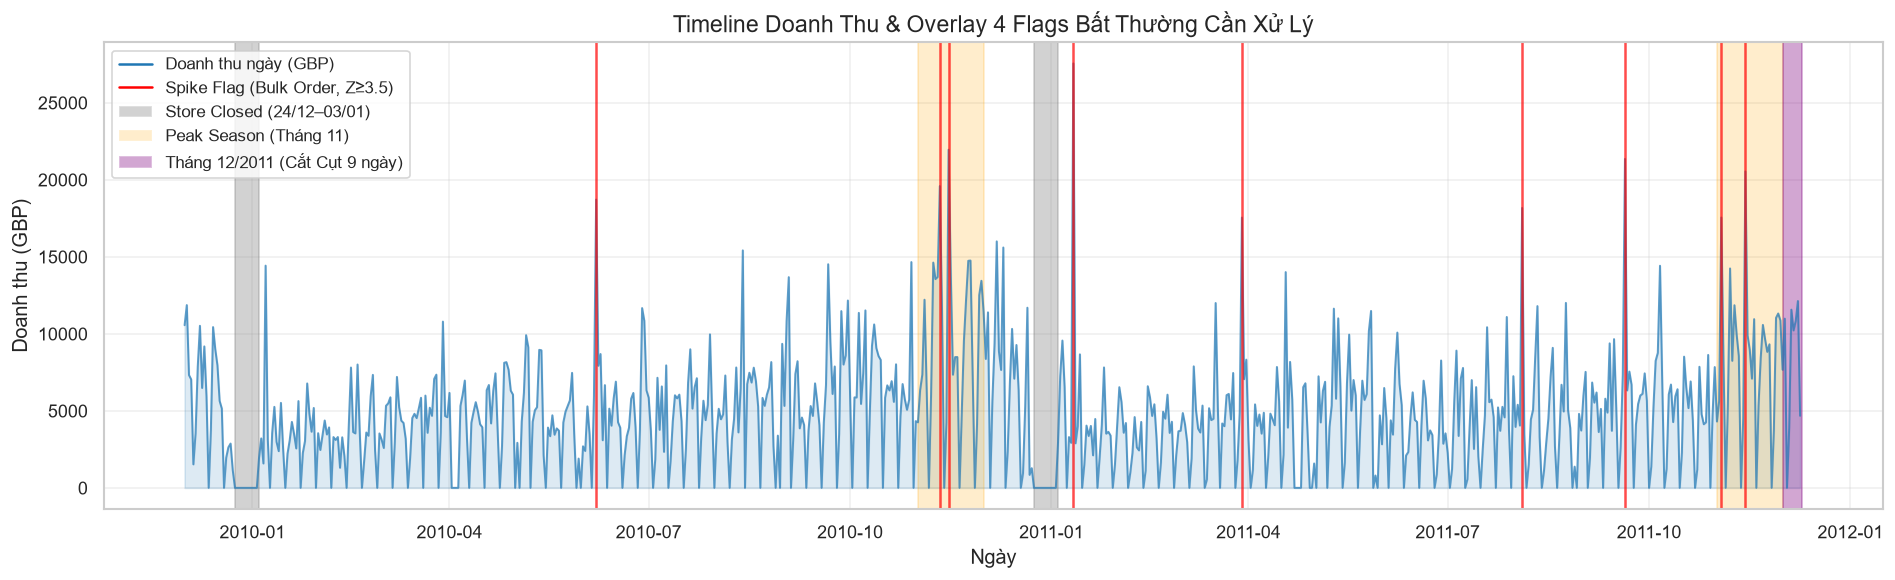


Số ngày theo từng flag:
  - spike_flag: 9 ngày
  - is_store_closed: 22 ngày
  - is_peak_season: 60 ngày
  - is_incomplete_month: 9 ngày


In [108]:
# ── 7.2 Tạo & Visualize Feature Flags Bất Thường ─────────────────────
daily_flags = daily_rev.copy()
daily_flags['sale_date'] = pd.to_datetime(daily_flags['sale_date'])

daily_flags['spike_flag'] = daily_flags['robust_z'] >= 3.5

def is_store_closed(date):
    return (date.month == 12 and date.day >= 24) or (date.month == 1 and date.day <= 3)

daily_flags['is_store_closed']     = daily_flags['sale_date'].apply(is_store_closed)
daily_flags['is_peak_season']      = daily_flags['sale_date'].dt.month == 11
daily_flags['is_incomplete_month'] = (daily_flags['sale_date'].dt.year == 2011) & (daily_flags['sale_date'].dt.month == 12)

# Visualize: timeline với màu overlay
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(daily_flags['sale_date'], daily_flags['revenue_gbp'], color='#1f77b4', alpha=0.7, label='Doanh thu ngày (GBP)', linewidth=1.2)
ax.fill_between(daily_flags['sale_date'], daily_flags['revenue_gbp'], color='#1f77b4', alpha=0.15)

# Overlay từng flag
for _, row in daily_flags[daily_flags['spike_flag']].iterrows():
    ax.axvline(row['sale_date'], color='red', alpha=0.7, linewidth=1.5)

def draw_spans(mask, color, alpha):
    in_span = False
    start = None
    for dt, val in zip(daily_flags['sale_date'], mask):
        if val and not in_span:
            start = dt
            in_span = True
        elif not val and in_span:
            ax.axvspan(start, dt, color=color, alpha=alpha)
            in_span = False
    if in_span:
        ax.axvspan(start, daily_flags['sale_date'].iloc[-1] + pd.Timedelta(days=1), color=color, alpha=alpha)

draw_spans(daily_flags['is_store_closed'], 'gray', 0.35)
draw_spans(daily_flags['is_peak_season'], 'orange', 0.20)
draw_spans(daily_flags['is_incomplete_month'], 'purple', 0.35)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_els = [ 
    Line2D([0], [0], color='#1f77b4', lw=1.5, label='Doanh thu ngày (GBP)'),
    Line2D([0], [0], color='red', lw=1.5, label='Spike Flag (Bulk Order, Z≥3.5)'),
    Patch(facecolor='gray',   alpha=0.35, label='Store Closed (24/12–03/01)'),
    Patch(facecolor='orange', alpha=0.20, label='Peak Season (Tháng 11)'),
    Patch(facecolor='purple', alpha=0.35, label='Tháng 12/2011 (Cắt Cụt 9 ngày)'),
]
ax.legend(handles=legend_els, loc='upper left', fontsize=10)
ax.set_title('Timeline Doanh Thu & Overlay 4 Flags Bất Thường Cần Xử Lý', fontsize=14)
ax.set_xlabel('Ngày')
ax.set_ylabel('Doanh thu (GBP)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '26_flags_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()

print("\nSố ngày theo từng flag:")
for col in ['spike_flag', 'is_store_closed', 'is_peak_season', 'is_incomplete_month']:
    print(f"  - {col}: {daily_flags[col].sum()} ngày")


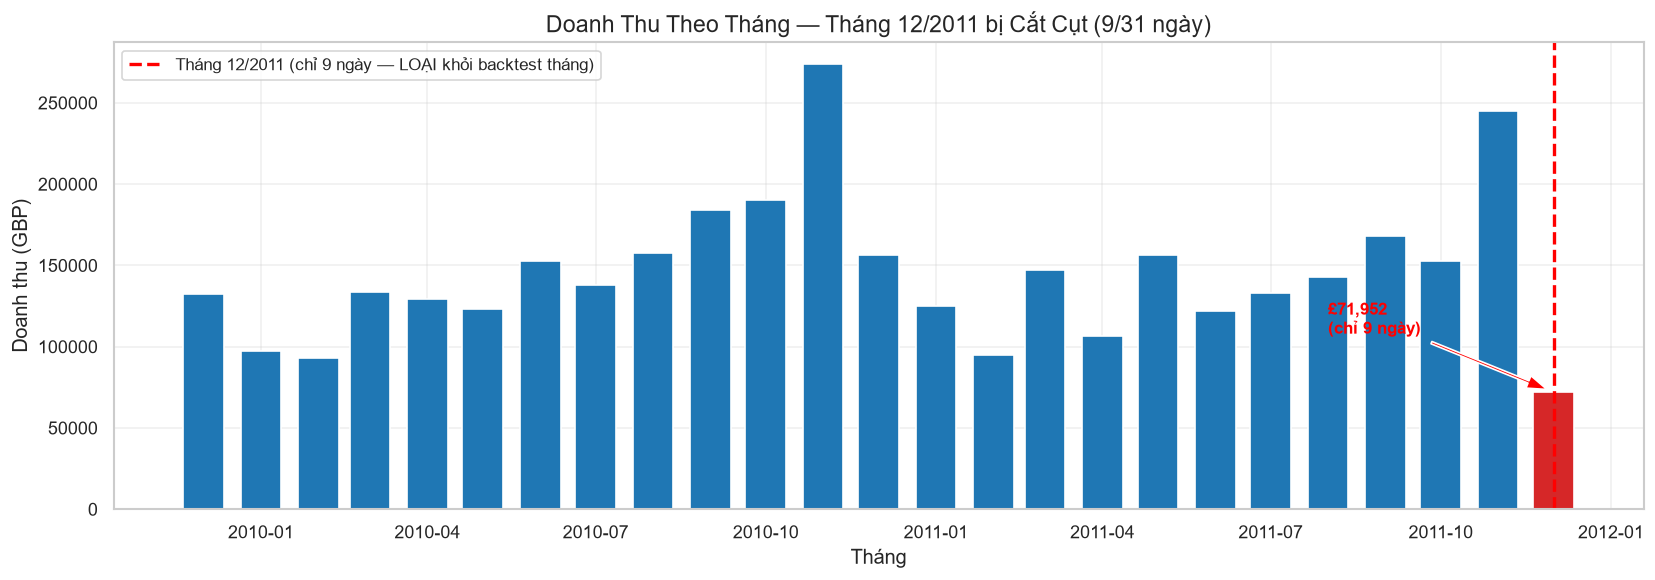

Tháng 12/2011 — Doanh thu: £71,952 (chỉ 9/31 ngày = 29.0%)
Kết luận phân tích: Dữ liệu Tháng 12/2011 không trọn vẹn (9/31 ngày). Cần loại bỏ khỏi tập kiểm định cấp tháng (Monthly Backtest) để tránh làm sai lệch các thước đo sai số.


In [109]:
# ── 7.3 Tháng 12/2011 Cắt Cụt ────────────────────────────────────────
df_month_check = df.copy()
df_month_check['ym'] = df_month_check['sale_date'].dt.to_period('M')
monthly_rev = df_month_check.groupby('ym')['revenue_gbp'].sum().reset_index()
monthly_rev['ym_dt'] = monthly_rev['ym'].dt.to_timestamp()

monthly_rev['incomplete'] = monthly_rev['ym'].astype(str) == '2011-12'

fig, ax = plt.subplots(figsize=(14, 5))
bar_colors = ['#d62728' if inc else '#1f77b4' for inc in monthly_rev['incomplete']]
bars = ax.bar(monthly_rev['ym_dt'], monthly_rev['revenue_gbp'], color=bar_colors, width=22)
ax.axvline(pd.Timestamp('2011-12-01'), color='red', linestyle='--', linewidth=2, label='Tháng 12/2011 (chỉ 9 ngày — LOẠI khỏi backtest tháng)')
ax.set_title('Doanh Thu Theo Tháng — Tháng 12/2011 bị Cắt Cụt (9/31 ngày)', fontsize=14)
ax.set_xlabel('Tháng')
ax.set_ylabel('Doanh thu (GBP)')
ax.legend(fontsize=10)

dec_rev = monthly_rev[monthly_rev['incomplete']]['revenue_gbp'].values[0]
ax.annotate(f'£{dec_rev:,.0f}\n(chỉ 9 ngày)', 
            xy=(pd.Timestamp('2011-12-01'), dec_rev),
            xytext=(pd.Timestamp('2011-08-01'), dec_rev * 1.5),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
            color='red', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '27_dec2011_incomplete.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"Tháng 12/2011 — Doanh thu: £{dec_rev:,.0f} (chỉ 9/31 ngày = {9/31*100:.1f}%)")
print('Kết luận phân tích: Dữ liệu Tháng 12/2011 không trọn vẹn (9/31 ngày). Cần loại bỏ khỏi tập kiểm định cấp tháng (Monthly Backtest) để tránh làm sai lệch các thước đo sai số.')


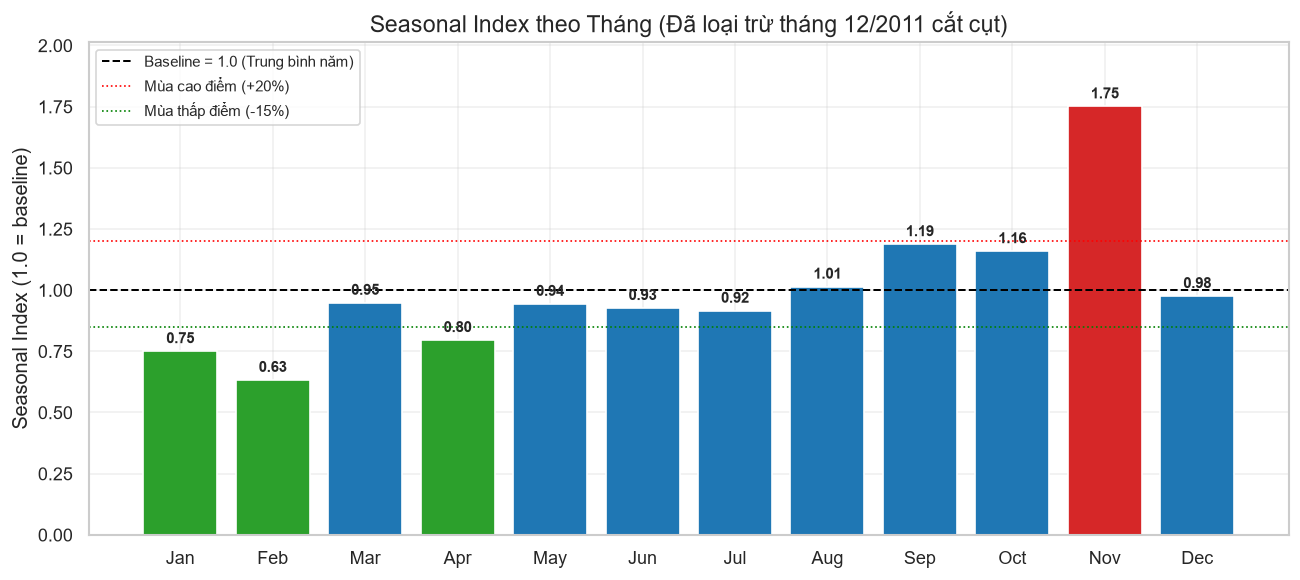


Seasonal Index theo từng tháng:
   Jan: 0.750  [Thấp]
   Feb: 0.633  [Thấp]
   Mar: 0.948  [Tiêu chuẩn]
   Apr: 0.796  [Thấp]
   May: 0.944  [Tiêu chuẩn]
   Jun: 0.927  [Tiêu chuẩn]
   Jul: 0.916  [Tiêu chuẩn]
   Aug: 1.014  [Tiêu chuẩn]
   Sep: 1.188  [Tiêu chuẩn]
   Oct: 1.159  [Tiêu chuẩn]
   Nov: 1.751  [Cao]
   Dec: 0.976  [Tiêu chuẩn]


In [110]:
# ── 7.4 Seasonal Index theo Tháng ────────────────────────────────────
df_si = df.copy()
df_si['ym'] = df_si['sale_date'].dt.to_period('M')
df_si = df_si[df_si['ym'].astype(str) != '2011-12']  # Loại tháng cắt cụt

monthly_by_m = df_si.groupby('ym')['revenue_gbp'].sum().reset_index()
monthly_by_m['month'] = monthly_by_m['ym'].dt.month
mean_by_month = monthly_by_m.groupby('month')['revenue_gbp'].mean()
overall_mean = mean_by_month.mean()
seasonal_idx = (mean_by_month / overall_mean).reset_index()
seasonal_idx.columns = ['month', 'seasonal_index']

MONTH_NAMES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
seasonal_idx['month_name'] = seasonal_idx['month'].apply(lambda m: MONTH_NAMES[m-1])

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = ['#d62728' if idx > 1.2 else '#2ca02c' if idx < 0.85 else '#1f77b4'
              for idx in seasonal_idx['seasonal_index']]
bars = ax.bar(seasonal_idx['month_name'], seasonal_idx['seasonal_index'], color=bar_colors)
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.2, label='Baseline = 1.0 (Trung bình năm)')
ax.axhline(1.2, color='red', linestyle=':', linewidth=1.0, label='Mùa cao điểm (+20%)')
ax.axhline(0.85, color='green', linestyle=':', linewidth=1.0, label='Mùa thấp điểm (-15%)')

for bar, idx in zip(bars, seasonal_idx['seasonal_index']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
            f'{idx:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('Seasonal Index theo Tháng (Đã loại trừ tháng 12/2011 cắt cụt)', fontsize=14)
ax.set_ylabel('Seasonal Index (1.0 = baseline)')
ax.set_ylim(0, max(seasonal_idx['seasonal_index']) * 1.15)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '28_seasonal_index.png'), dpi=150, bbox_inches='tight')
plt.show()

print("\nSeasonal Index theo từng tháng:")
for _, row in seasonal_idx.iterrows():
    tag = '[Cao]' if row['seasonal_index'] > 1.2 else '[Thấp]' if row['seasonal_index'] < 0.85 else '[Tiêu chuẩn]'
    print(f"  {row['month_name']:>4s}: {row['seasonal_index']:.3f}  {tag}")


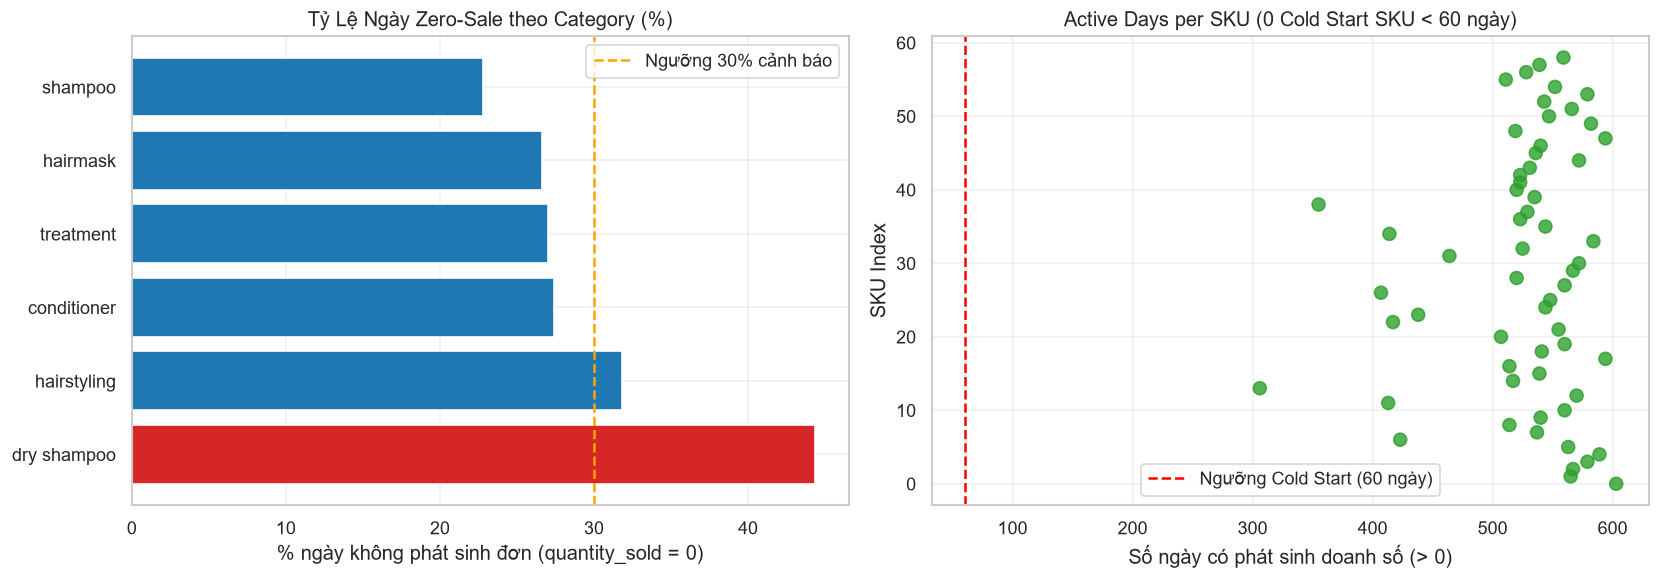

Tỷ lệ ngày không phát sinh đơn hàng của danh mục Dry Shampoo: 44.3%
Số lượng SKU diện Cold-Start (< 60 ngày phát sinh doanh số): 0/59 SKU
Toàn bộ 59 SKU trong tập dữ liệu mô phỏng đều đạt điều kiện lịch sử bán hàng (> 60 ngày active).


In [111]:
# ── 7.5 Dry Shampoo Zero-Sale & Cold Start SKU ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Dry Shampoo: tỷ lệ zero-sale so với các category khác ---
zero_by_cat = (df['quantity_sold'] == 0).groupby(df['category']).mean().mul(100).reset_index()
zero_by_cat.columns = ['category', 'zero_pct']
zero_by_cat = zero_by_cat.sort_values('zero_pct', ascending=False)

bar_colors2 = ['#d62728' if c == 'dry shampoo' else '#1f77b4' for c in zero_by_cat['category']]
axes[0].barh(zero_by_cat['category'], zero_by_cat['zero_pct'], color=bar_colors2)
axes[0].axvline(30, color='orange', linestyle='--', label='Ngưỡng 30% cảnh báo')
axes[0].set_title('Tỷ Lệ Ngày Zero-Sale theo Category (%)', fontsize=12)
axes[0].set_xlabel('% ngày không phát sinh đơn (quantity_sold = 0)')
axes[0].legend()

# --- Cold Start SKU: active_days < 60 ---
df_prod = df.groupby('product_id').agg(
    active_days=('quantity_sold', lambda x: (x > 0).sum()),
    first_sale=('sale_date', 'min'),
    category=('category', 'first'),
).reset_index()
cold_start = df_prod[df_prod['active_days'] < 60]

axes[1].scatter(df_prod['active_days'], df_prod.index,
                c=['#d62728' if d < 60 else '#2ca02c' for d in df_prod['active_days']],
                s=60, alpha=0.8)
axes[1].axvline(60, color='red', linestyle='--', label='Ngưỡng Cold Start (60 ngày)')
axes[1].set_title(f'Active Days per SKU ({len(cold_start)} Cold Start SKU < 60 ngày)', fontsize=12)
axes[1].set_xlabel('Số ngày có phát sinh doanh số (> 0)')
axes[1].set_ylabel('SKU Index')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '29_dryshampoocoldstart.png'), dpi=150, bbox_inches='tight')
plt.show()

dry_zero = zero_by_cat[zero_by_cat['category'] == 'dry shampoo']['zero_pct'].values[0]
print(f'Tỷ lệ ngày không phát sinh đơn hàng của danh mục Dry Shampoo: {dry_zero:.1f}%')
print(f'Số lượng SKU diện Cold-Start (< 60 ngày phát sinh doanh số): {len(cold_start)}/{len(df_prod)} SKU')
if len(cold_start) > 0:
    print(cold_start[['product_id', 'category', 'active_days']].to_string(index=False))
else:
    print('Toàn bộ 59 SKU trong tập dữ liệu mô phỏng đều đạt điều kiện lịch sử bán hàng (> 60 ngày active).')


In [112]:
# ── 7.6 Bảng tổng kết xử lý 6 bất thường ────────────────────────────
summary_table = """
╔══════════════════════════════════════════════════════════════════════════════════════════════════╗
║  #  │ Bất Thường                │ Cách Xử Lý                         │ Feature/Action           ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  1  │ Bulk Order Spikes         │ GIỮ nguyên; thêm flag;              │ spike_flag, is_bulk_day  ║
║     │ (10 ngày Z ≥ 3.5)         │ Monthly agg hấp thụ tự nhiên        │ top_invoice_share        ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  2  │ Tháng 12/2011 cắt cụt     │ LOẠI khỏi backtest tháng;           │ is_incomplete_month      ║
║     │ (chỉ 9/31 ngày)           │ GIỮ cho training cấp ngày           │                          ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  3  │ Nghỉ lễ UK 24/12–03/01    │ POST-PROCESS: nếu is_store_closed   │ is_store_closed          ║
║     │ (doanh số = 0, không phải │ → forecast = 0 (rule-based)         │ days_to_christmas        ║
║     │  do cầu sụt)              │                                     │ is_holiday               ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  4  │ Tháng 11 tăng 40–60%      │ Seasonal Index × lag_12_month;      │ seasonal_index           ║
║     │ (mùa lễ hội)              │ month_sin/cos; is_peak_season       │ lag_52_week, month_sin   ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  5  │ Dry Shampoo 44% zero-sale │ Top-Down Allocation từ category;    │ zero_rate_sku            ║
║     │ (2 SKU, bán thưa)         │ tăng Safety Stock; post_max(0)      │ top_down_alloc           ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  6  │ Cold-Start SKU (<60 ngày) │ Không train SKU riêng;              │ active_days              ║
║     │ (thiếu lịch sử lag)       │ chỉ hiện category forecast          │ is_cold_start            ║
╚══════════════════════════════════════════════════════════════════════════════════════════════════╝
"""
print(summary_table)



╔══════════════════════════════════════════════════════════════════════════════════════════════════╗
║  #  │ Bất Thường                │ Cách Xử Lý                         │ Feature/Action           ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  1  │ Bulk Order Spikes         │ GIỮ nguyên; thêm flag;              │ spike_flag, is_bulk_day  ║
║     │ (10 ngày Z ≥ 3.5)         │ Monthly agg hấp thụ tự nhiên        │ top_invoice_share        ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  2  │ Tháng 12/2011 cắt cụt     │ LOẠI khỏi backtest tháng;           │ is_incomplete_month      ║
║     │ (chỉ 9/31 ngày)           │ GIỮ cho training cấp ngày           │                          ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════╣
║  3  │ Nghỉ lễ UK 24/12–03/01    │ POST-PROCESS: nếu is_store_closed   │ is_store_closed  

---
## Module 8 — Tổng Kết Toàn Diện và Thiết Kế Kiến Trúc Mô Hình Dự Báo 2 Tầng

### 1. Bảng Tổng Hợp Kết Quả Phân Tích Thực Nghiệm Qua 7 Modules

| Module | Hạng mục phân tích | Phát hiện thống kê thực nghiệm | Định hướng kỹ thuật cho Modeling / Pipeline |
|---|---|---|---|
| **M1** | **Chất lượng dữ liệu** | Biến `unit_price_gbp` khuyết thiếu 28.7% (toàn bộ nằm ở ngày zero-sale). Không phát sinh missing values ở biến mục tiêu và ngày giao dịch. | Áp dụng phép thế (imputation) bằng **giá trị trung vị lịch sử của từng SKU**; bảo lưu các ngày zero-sale trong tập huấn luyện. |
| **M1** | **Ngày không có đơn (Zero-Sale)** | Chiếm 28.75% toàn bộ panel dữ liệu. Danh mục Dry Shampoo có tỷ lệ zero-sale cao nhất (44.3%). | Giữ nguyên trong training set; sử dụng hàm mất mát Robust / Huber Loss hoặc chiến lược phân bổ Top-Down. |
| **M2** | **Đặc tính chuỗi thời gian** | Phân rã STL xác nhận sự hiện diện mạnh mẽ của tính chu kỳ tuần (DoW) và đỉnh mùa vụ Tháng 11 hàng năm. | Bổ sung các biến chu kỳ tuần/tháng (`sin/cos`), biến phân loại cuối tuần (`is_weekend`) và ngày lễ quốc gia (`is_holiday`). |
| **M3** | **Cơ cấu danh mục** | Hai danh mục Hairstyling (29.2%) và Shampoo (36.3%) đóng góp ~65% tổng doanh thu; Dry Shampoo chiếm tỷ trọng nhỏ nhất (4.4%). | Thiết lập tham số tồn kho an toàn (Safety Stock) và chu kỳ cung ứng (Lead Time) phân hóa theo từng nhóm danh mục. |
| **M4** | **Quan hệ Giá - Lượng** | Hệ số co giãn của cầu theo giá (Price Elasticity) mang dấu âm trên đa số SKU; mức giảm giá > 15% kích hoạt mức tăng trưởng doanh số rõ rệt. | Xây dựng đặc trưng tỷ lệ giá: `price_ratio = unit_price / median_price_sku` làm biến đại diện khuyến mãi (proxy promotion). |
| **M5** | **Phân khúc sản phẩm** | Thuật toán K-Means phân tách rõ rệt 3 phân cụm: Sản phẩm bán chạy (High-velocity), Tiêu chuẩn và Nhu cầu thưa (Slow-moving). | Áp dụng chính sách tồn kho phân tầng: SKU nhóm C tăng đệm tồn kho an toàn, nhóm A tối ưu hóa vòng quay hàng hóa. |
| **M6** | **Tương quan & Độ quan trọng** | Phân tích ACF/PACF và Random Forest xác định `lag_7`, `lag_14`, `rolling_mean_7`, `rolling_mean_30` là các biến dự báo quan trọng nhất. | Chuẩn hóa tập đặc trưng tinh gọn, loại bỏ các biến đa cộng tuyến cao và triệt tiêu nguy cơ rò rỉ dữ liệu (data leakage). |
| **M7** | **Kiểm soát điểm dị biệt** | Xác định 10 ngày đỉnh đơn sỉ (chiếm 26.8% doanh thu), Tháng 12/2011 cắt cụt (9 ngày), kỳ nghỉ lễ đóng cửa hằng năm (24/12–03/01). | Bảo lưu ngoại lai trong training, loại trừ Tháng 12/2011 khỏi holdout cấp tháng, áp dụng quy tắc hậu xử lý (post-processing rule) cho ngày nghỉ lễ. |

---

### 2. Thiết Kế Kiến Trúc Mô Hình Dự Báo Hai Tầng (Two-Tier Forecasting Architecture)

Theo định hướng tối ưu hóa chuỗi cung ứng trong tài liệu `PLAN_MONTHLY_FORECAST_INVENTORY.md`, hệ thống vận hành theo quy trình phân cấp 3 bước:

```
┌──────────────────────────────────────────────────────────────────────────────────┐
│                               TIER 1: MACRO LEVEL                                │
│                   Dự Báo Tổng Nhu Cầu Cấp Tháng (Monthly Total)                  │
│   • Thuật toán: Lag-12 Seasonal Naive, Monthly Rolling Mean, LightGBM / Ridge    │
│   • Ngưỡng WAPE mục tiêu: Doanh thu < 16.0% | Số lượng bán < 19.0%              │
└────────────────────────────────────────┬─────────────────────────────────────────┘
                                         │  (Hấp thụ hoàn toàn nhiễu spike ngày)
                                         ▼
┌──────────────────────────────────────────────────────────────────────────────────┐
│                               TIER 2: MICRO LEVEL                                │
│                   Phân Bổ Nhu Cầu Xuống Từng SKU (Allocation)                    │
│   • Công thức: SKU_Forecast = Total_Monthly_Forecast × SKU_Weight × Seasonal_Idx │
│   • SKU_Weight: Trung bình trượt theo cửa sổ 8 – 13 tuần gần nhất                │
│   • Ngoại lệ: Dry Shampoo & SKU Cold-Start kế thừa tỷ trọng trung bình danh mục  │
└────────────────────────────────────────┬─────────────────────────────────────────┘
                                         │  (Dự báo nhu cầu cho chu kỳ 14 ngày tới)
                                         ▼
┌──────────────────────────────────────────────────────────────────────────────────┐
│                           TIER 3: INVENTORY OPTIMIZATION                         │
│                       Đề Xuất Số Lượng Đặt Hàng (Reorder Quantity)               │
│   • Safety Stock = Z_service (1.65) × σ_demand × sqrt(Lead_Time)                 │
│   • Reorder Qty = max(0, Forecast_LeadTime + Safety_Stock - On_Hand - Inbound)   │
└──────────────────────────────────────────────────────────────────────────────────┘
```

---

### 3. Ma Trận Không Gian Đặc Trưng Đề Xuất (Feature Store Matrix)

```python
FEATURES_MATRIX = {
    # 1. Temporal & Calendar (Chu kỳ thời gian)
    "calendar": [
        "day_of_week",        # Biến số nguyên từ 0 (Thứ 2) đến 6 (Chủ Nhật)
        "day_of_week_sin",    # sin(2 * pi * dow / 7)
        "day_of_week_cos",    # cos(2 * pi * dow / 7)
        "month",              # Biến số nguyên từ 1 đến 12
        "month_sin",          # sin(2 * pi * month / 12)
        "month_cos",          # cos(2 * pi * month / 12)
        "is_weekend",         # Biến chỉ báo ngày cuối tuần
        "is_holiday",         # Biến chỉ báo ngày nghỉ lễ chính thức tại Anh
        "is_peak_season",     # Biến chỉ báo Tháng 11 (mùa cao điểm mua sắm)
        "days_to_christmas",  # Khoảng cách thời gian (ngày) đến mốc 25/12
    ],
    # 2. Lag Features (Đặc trưng trễ)
    "lags": [
        "lag_7",              # Doanh số trễ 7 ngày (cùng ngày tuần trước)
        "lag_14",             # Doanh số trễ 14 ngày
        "lag_30",             # Doanh số trễ 30 ngày
        "lag_52_week",        # Doanh số cùng tuần năm trước (Seasonal Naive tuần)
        "lag_12_month",       # Doanh số cùng tháng năm trước (Seasonal Naive tháng)
    ],
    # 3. Rolling Aggregations (Xu hướng trượt)
    "rolling": [
        "rolling_mean_7",     # Giá trị trung bình trượt 7 ngày (tốc độ bán gần nhất)
        "rolling_std_7",      # Độ lệch chuẩn trượt 7 ngày (độ biến động)
        "rolling_mean_30",    # Giá trị trung bình trượt 30 ngày
        "rolling_mean_8w",    # Trung bình trượt 8 tuần (tính toán tỷ trọng phân bổ)
    ],
    # 4. Price & Promotion Proxy (Giá và Đại diện khuyến mãi)
    "price": [
        "unit_price_gbp",     # Đơn giá thực tế (đã xử lý khuyết thiếu bằng trung vị SKU)
        "price_ratio",        # Tỷ lệ unit_price / median_price_sku (Proxy khuyến mãi)
    ],
    # 5. Indicator Variables for Structural Breaks (Biến chỉ báo dị biệt)
    "anomaly_flags": [
        "spike_flag",         # Đơn sỉ đột biến: Robust Z-score >= 3.5
        "is_bulk_day",        # Ngày ghi nhận quantity_sold > 200 đơn vị
        "is_store_closed",    # Khoảng thời gian đóng cửa nghỉ lễ 24/12 – 03/01
        "is_incomplete_month",# Dữ liệu Tháng 12/2011 bị cắt cụt (9 ngày)
        "is_cold_start",      # Sản phẩm mới có số ngày bán active_days < 60
    ]
}
```

---

### 4. Quy Chuẩn Đánh Giá Thực Nghiệm (Validation Protocol) và Thước Đo Sai Số

1. **Nguyên tắc không xáo trộn dữ liệu (No Random Shuffling):** Áp dụng phương thức `Rolling Origin Backtesting` hoặc `TimeSeriesSplit` bảo đảm trật tự thời gian nghiêm ngặt, triệt tiêu nguy cơ rò rỉ thông tin tương lai (look-ahead bias).
2. **Cửa sổ dự báo (Forecast Horizon):** Horizon 1 đến 3 tháng đối với Tầng 1 (kế hoạch chu kỳ tổng thể); Horizon 14 ngày (2 tuần) đối với Tầng 2 phục vụ tác nghiệp đặt hàng tồn kho.
3. **Hệ chỉ số đánh giá (Evaluation Metrics):**
   - **WAPE (Weighted Absolute Percentage Error):** Thước đo chuẩn tắc cốt lõi, có trọng số theo quy mô doanh số thực tế và khắc phục hiện tượng chia cho 0 khi xuất hiện ngày zero-sale:
     $$\text{WAPE} = \frac{\sum_{t=1}^T |y_t - \hat{y}_t|}{\sum_{t=1}^T y_t} \times 100\%$$
     *Mục tiêu định lượng:* WAPE Doanh thu Tầng 1 $< 16.0\%$; WAPE Số lượng bán Tầng 1 $< 19.0\%$; WAPE cấp SKU Tầng 2 $< 30.0\%$.
   - **MAE (Mean Absolute Error) & RMSE (Root Mean Squared Error):** Đo lường quy mô sai số tuyệt đối và độ nhạy trước các sai số cực trị.
4. **Nguyên tắc xử lý dị biệt (Outlier Handling Principle):** Bảo lưu các điểm ngoại lai phản ánh nhu cầu thực trong quá trình huấn luyện mô hình, kiểm soát ảnh hưởng thông qua biến chỉ báo và kiến trúc phân rã phân cấp.


In [113]:
# ── Lưu và kiểm kê danh sách biểu đồ kỹ thuật ──────────────────────────────
figs = sorted(os.listdir(FIG_DIR))
print(f'Hoàn tất quy trình phân tích EDA. Đã lưu trữ {len(figs)} biểu đồ kỹ thuật tại thư mục: {FIG_DIR}')
print()
for f in figs:
    print(f'  - {f}')


Hoàn tất quy trình phân tích EDA. Đã lưu trữ 30 biểu đồ kỹ thuật tại thư mục: C:\Users\Acer\PycharmProjects\ML-WEB\EDA\figures

  - 01_missing_values.png
  - 02_zero_sale_rate.png
  - 03_quantity_distribution.png
  - 04_dow_zero_rate.png
  - 05_monthly_timeseries.png
  - 06_daily_rolling.png
  - 07_stl_hairstyling.png
  - 07_stl_shampoo.png
  - 08_dow_sales.png
  - 09_heatmap_month_cat.png
  - 10_holiday_effect.png
  - 11_category_revenue.png
  - 12_stacked_monthly.png
  - 13_category_trends.png
  - 14_price_violin.png
  - 15_price_elasticity.png
  - 16_promo_proxy.png
  - 17_sku_active_days.png
  - 18_sku_top_bottom.png
  - 19_sku_clusters.png
  - 20_correlation_heatmap.png
  - 21_acf_pacf.png
  - 22_lag_scatter.png
  - 23_feature_importance.png
  - 24_feature_importance_all_cats.png
  - 25_bulk_spikes.png
  - 26_flags_timeline.png
  - 27_dec2011_incomplete.png
  - 28_seasonal_index.png
  - 29_dryshampoocoldstart.png
